In [1]:
import subprocess, sys
def _pip(*p): subprocess.run([sys.executable,"-m","pip","install","-q",*p], check=False)
_pip("xarray","netcdf4","cdsapi","global-land-mask")
print("deps ready")

deps ready


In [2]:
import os, gc, json, math, time, random, warnings
from dataclasses import dataclass, field
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib as mpl
warnings.filterwarnings("ignore")
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

SEED=42; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED); torch.backends.cudnn.benchmark=True
    torch.backends.cuda.matmul.allow_tf32=True; torch.backends.cudnn.allow_tf32=True
DEVICE=torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_DTYPE=torch.bfloat16 if (DEVICE.type=="cuda" and torch.cuda.is_bf16_supported()) else torch.float16
print("torch",torch.__version__,"| device",DEVICE,"| amp",AMP_DTYPE)
if DEVICE.type=="cuda": print("GPU:",torch.cuda.get_device_name(0))
mpl.rcParams.update({"figure.dpi":120,"font.family":"serif","font.size":11,
    "axes.titlesize":12.5,"axes.spines.top":False,"axes.spines.right":False})

torch 2.11.0+cu128 | device cuda | amp torch.bfloat16
GPU: NVIDIA A100-SXM4-80GB


In [3]:
BASE=Path(".")
try:
    from google.colab import drive; drive.mount("/content/drive")
    BASE=Path("/content/drive/MyDrive/MSc Dissertation"); BASE.mkdir(parents=True,exist_ok=True)
except Exception: print("Not on Colab — using local dir.")
print("BASE =",BASE.resolve())

Mounted at /content/drive
BASE = /content/drive/MyDrive/MSc Dissertation


In [4]:
@dataclass
class Config:
    RUN_MODE: str = "auto"
    AREA: tuple = (56.0,-6.0,50.0,2.0); GRID: float = 0.25
    YEARS: tuple = tuple(range(2015,2027))
    VARIABLES: tuple = (
        "10m_u_component_of_wind","10m_v_component_of_wind",
        "100m_u_component_of_wind","100m_v_component_of_wind",
        "instantaneous_10m_wind_gust","10m_wind_gust_since_previous_post_processing",
        "convective_available_potential_energy",
        "k_index","total_column_water_vapour","boundary_layer_height",
        "mean_sea_level_pressure","surface_pressure","2m_temperature","2m_dewpoint_temperature")
    RAW_DIR: Path = field(default_factory=lambda: BASE/"era5_england_raw_full")
    CACHE: Path = field(default_factory=lambda: BASE/"heich_cache")
    TIME_STRIDE: int = 1
    MAX_CELLS: int = 0          # only affects EDA aggregates; model uses the full grid
    LAND_ONLY: bool = True      # score on the same land+coastal cells as the gradient-boosted model (fair comparison)
    POT_Q: float = 0.98
    DECLUS_HRS: int = 24
    HIST: int = 48              # hours of maps fed to the ConvGRU
    LEAD: int = 24              # predict an exceedance in (t, t+LEAD]
    SAMPLE_STRIDE: int = 3      # stride between origin times
    TRAIN_FRAC: float = 0.70; VAL_FRAC: float = 0.15
    # model
    HID: int = 24               # ConvGRU hidden channels
    KSIZE: int = 3
    DROPOUT: float = 0.3
    XI_CLAMP: float = 0.4       # GPD shape bounded to [-XI_CLAMP, XI_CLAMP]
    XI_INIT: float = -0.13      # start the GPD shape near the EVT estimate so it trains
    # training
    BATCH: int = 16
    EPOCHS: int = 40
    LR: float = 1e-3
    WEIGHT_DECAY: float = 1e-2
    PATIENCE: int = 12
    FOCAL_GAMMA: float = 2.0
    LAMBDA_SEV: float = 1.0
    # physics informed terms
    USE_PHYSICS: bool = True
    LAMBDA_AUX: float = 0.3      # supervised gust tendency head
    LAMBDA_PHYS: float = 0.05    # weight on the advection residual (soft prior)
    DT_HOURS: float = 1.0        # tendency step used by the residual

CFG=Config(); CFG.RAW_DIR.mkdir(parents=True,exist_ok=True); CFG.CACHE.mkdir(parents=True,exist_ok=True)
print("Config ready | RUN_MODE",CFG.RUN_MODE,"| RAW_DIR",CFG.RAW_DIR)

Config ready | RUN_MODE auto | RAW_DIR /content/drive/MyDrive/MSc Dissertation/era5_england_raw_full


In [5]:
# ERA5 downloader (only used in RUN_MODE="full" or if you call it explicitly)
def download_era5(cfg):
    import cdsapi
    c = cdsapi.Client()
    cfg.RAW_DIR.mkdir(parents=True, exist_ok=True)
    N, W, S, E = cfg.AREA
    files = []
    for yr in cfg.YEARS:
        fp = cfg.RAW_DIR / f"era5_england_{yr}.nc"
        if fp.exists():
            print(f"  [{yr}] present — skip"); files.append(fp); continue
        print(f"  [{yr}] requesting from CDS …")
        try:
            c.retrieve("reanalysis-era5-single-levels", {
                "product_type": "reanalysis",
                "variable": list(cfg.VARIABLES),
                "year": str(yr),
                "month": [f"{m:02d}" for m in range(1, 13)],
                "day":   [f"{d:02d}" for d in range(1, 32)],
                "time":  [f"{h:02d}:00" for h in range(24)],
                "area":  [N, W, S, E],
                "grid":  [cfg.GRID, cfg.GRID],
                "format": "netcdf",
            }, str(fp))
            files.append(fp)
        except Exception as e:
            print(f"  [{yr}] failed: {e}")
    return files

RAW_FILES = sorted(CFG.RAW_DIR.glob("*.nc"))
print(f"NetCDF files found in {CFG.RAW_DIR}: {len(RAW_FILES)}")
if CFG.RUN_MODE == "full" and not RAW_FILES:
    RAW_FILES = sorted(download_era5(CFG))

NetCDF files found in /content/drive/MyDrive/MSc Dissertation/era5_england_raw_full: 276


In [6]:
# canonical short-name mapping & robust ERA5 loader
RENAME = {
    "u10": "u10", "v10": "v10", "u100": "u100", "v100": "v100",
    "i10fg": "i10fg", "fg10": "fg10", "cape": "cape",
    "kx": "kx", "tcwv": "tcwv", "blh": "blh", "msl": "msl", "sp": "sp",
    "t2m": "t2m", "d2m": "d2m",
    # occasional alt names
    "10fg": "fg10", "instantaneous_10m_wind_gust": "i10fg",
}

def load_era5_netcdf(files, cfg):
    import xarray as xr
    ds = xr.open_mfdataset([str(f) for f in files], combine="by_coords",
                           engine="netcdf4", chunks={"time": 1500})
    # normalise coord names
    for a, b in [("latitude", "lat"), ("longitude", "lon"), ("valid_time", "time")]:
        if a in ds.dims or a in ds.coords:
            ds = ds.rename({a: b})
    # collapse ERA5T 'expver' if present
    if "expver" in ds.dims:
        ds = ds.mean("expver")
    elif "expver" in ds.coords:
        ds = ds.drop_vars("expver")
    ds = ds.rename({k: v for k, v in RENAME.items() if k in ds.variables})
    if cfg.TIME_STRIDE > 1:
        ds = ds.isel(time=slice(None, None, cfg.TIME_STRIDE))
    ds = ds.sortby("time").sortby("lat").sortby("lon")
    times = pd.DatetimeIndex(ds.time.values)
    lats = ds.lat.values.astype(np.float32)
    lons = ds.lon.values.astype(np.float32)
    fields = {}
    for name in ["u10","v10","u100","v100","i10fg","fg10","cape","kx","tcwv","blh","msl","sp","t2m","d2m"]:
        if name in ds.variables:
            fields[name] = ds[name].transpose("time","lat","lon").values.astype(np.float32)
    # unit tidy
    if "sp"  in fields: fields["sp"]  = fields["sp"] / 100.0     # Pa -> hPa
    if "msl" in fields: fields["msl"] = fields["msl"] / 100.0    # Pa -> hPa
    for k in ("t2m","d2m"):
        if k in fields: fields[k] = fields[k] - 273.15           # K -> degC
    ds.close()
    return times, lats, lons, fields

In [8]:
# load ERA5
if not RAW_FILES:
    raise FileNotFoundError(f"no ERA5 NetCDF files found in {CFG.RAW_DIR}")
times, lats, lons, FIELDS = load_era5_netcdf(RAW_FILES, CFG)

nlat, nlon = len(lats), len(lons)
T = len(times)
print("ERA5 data loaded")
print(f"  time : {times[0]} -> {times[-1]}  ({T:,} steps, stride={CFG.TIME_STRIDE}h)")
print(f"  grid : {nlat} lat x {nlon} lon = {nlat*nlon} cells  |  vars: {sorted(FIELDS)}")

ERA5 data loaded
  time : 2015-01-01 00:00:00 -> 2026-06-30 19:00:00  (100,772 steps, stride=1h)
  grid : 25 lat x 33 lon = 825 cells  |  vars: ['blh', 'cape', 'd2m', 'fg10', 'i10fg', 'kx', 'msl', 'sp', 't2m', 'tcwv', 'u10', 'u100', 'v10', 'v100']


In [9]:
# derived scalar fields + land mask + cell selection
def hypot(a, b): return np.sqrt(a*a + b*b)

FIELDS["ws10"]  = hypot(FIELDS["u10"], FIELDS["v10"]).astype(np.float32)
FIELDS["ws100"] = hypot(FIELDS["u100"], FIELDS["v100"]).astype(np.float32)
# gust: prefer instantaneous; fall back to fg10, then a gust-factor proxy
if "i10fg" in FIELDS:
    FIELDS["gust"] = FIELDS["i10fg"]
elif "fg10" in FIELDS:
    FIELDS["gust"] = FIELDS["fg10"]
else:
    FIELDS["gust"] = (1.4*FIELDS["ws10"]).astype(np.float32)

# clean sparse NaN gaps (real ERA5 has a few missing hours; NaN would poison
# percentiles/thresholds downstream). Interpolate in time per cell, then fill any
# fully-missing cell with the field mean.
def _clean_field(a):
    if not np.isnan(a).any():
        return a.astype(np.float32)
    Tt = a.shape[0]
    flat = pd.DataFrame(a.reshape(Tt, -1)).interpolate(limit_direction="both", axis=0)
    flat = flat.fillna(flat.mean())
    return flat.values.reshape(a.shape).astype(np.float32)

_nan_before = sum(int(np.isnan(v).sum()) for v in FIELDS.values())
if _nan_before:
    FIELDS = {k: _clean_field(v) for k, v in FIELDS.items()}
    _nan_after = sum(int(np.isnan(v).sum()) for v in FIELDS.values())
    print(f"NaN cleaning: {_nan_before:,} -> {_nan_after:,} missing values filled")

# land / coastal mask
land_mask = np.ones((nlat, nlon), dtype=bool)
if CFG.LAND_ONLY:
    try:
        from global_land_mask import globe
        LO, LA = np.meshgrid(lons, lats)
        land = globe.is_land(LA, LO)
        # keep land + one-cell coastal halo
        from scipy.ndimage import binary_dilation
        land_mask = binary_dilation(land, iterations=1)
        print(f"Land+coastal cells: {land_mask.sum()}/{land_mask.size}")
    except Exception as e:
        print("global_land_mask unavailable — keeping all cells:", e)

cell_ii, cell_jj = np.where(land_mask)
if CFG.MAX_CELLS and len(cell_ii) > CFG.MAX_CELLS:
    sel = np.linspace(0, len(cell_ii)-1, CFG.MAX_CELLS).astype(int)
    cell_ii, cell_jj = cell_ii[sel], cell_jj[sel]
N_CELLS = len(cell_ii)
print(f"Modelling {N_CELLS} cells | gust mean={FIELDS['gust'].mean():.2f}  max={FIELDS['gust'].max():.2f} m/s")

NaN cleaning: 1,849,650 -> 0 missing values filled
Land+coastal cells: 520/825
Modelling 520 cells | gust mean=9.26  max=44.62 m/s


In [10]:
# domain-aggregate helper series (mask to modelled cells)
def cell_stack(name):
    """Return array (T, N_CELLS) for a field, restricted to modelled cells."""
    return FIELDS[name][:, cell_ii, cell_jj]

gust_cells = cell_stack("gust")           # (T, N_CELLS)
dom_gust = gust_cells.mean(axis=1)        # domain-mean gust series
dom_gust_max = gust_cells.max(axis=1)     # domain-max gust (worst cell each hour)
month = times.month.values
hour = times.hour.values
print("Gust percentiles (m/s):",
      {p: round(float(np.nanpercentile(gust_cells, p)), 1) for p in (50, 90, 95, 98, 99, 99.9)})

Gust percentiles (m/s): {50: 8.1, 90: 14.6, 95: 16.7, 98: 19.2, 99: 20.9, 99.9: 26.1}


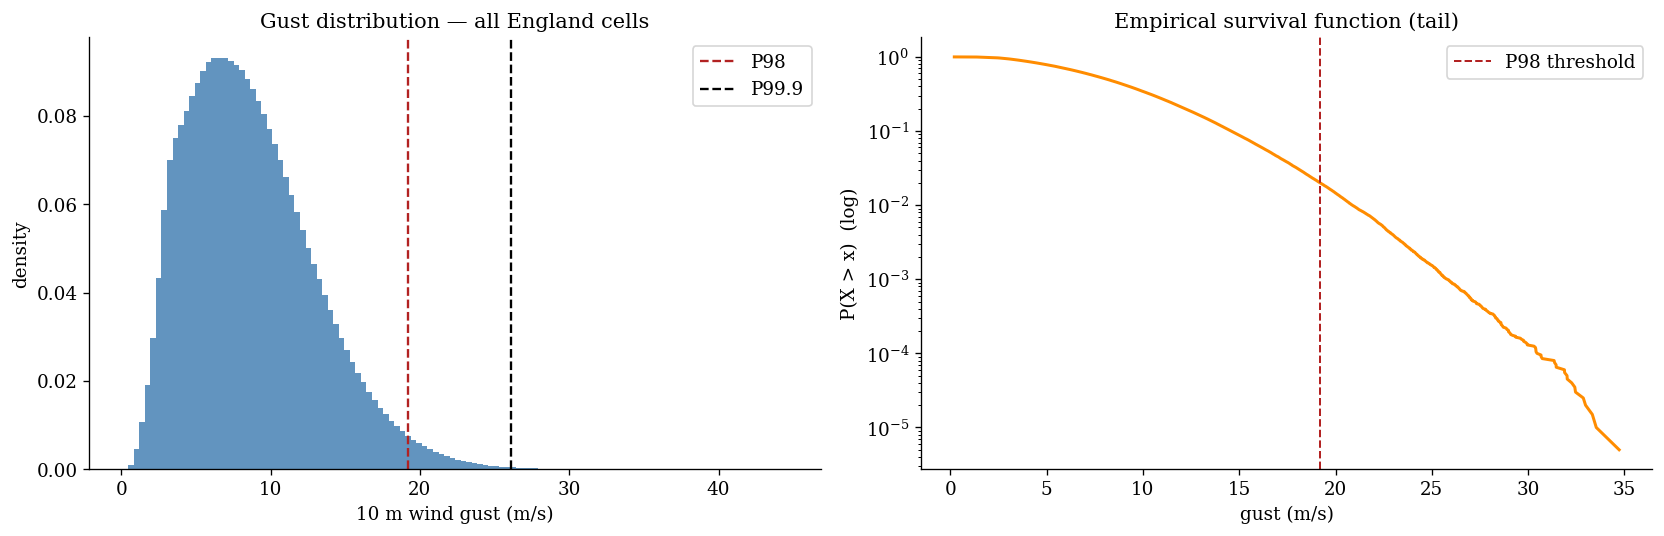

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
allg = gust_cells.ravel()
ax[0].hist(allg, bins=120, color="steelblue", alpha=0.85, density=True)
for p, c in [(98, "firebrick"), (99.9, "black")]:
    ax[0].axvline(np.nanpercentile(allg, p), color=c, ls="--", lw=1.4, label=f"P{p}")
ax[0].set_xlabel("10 m wind gust (m/s)"); ax[0].set_ylabel("density")
ax[0].set_title("Gust distribution — all England cells"); ax[0].legend()

# log-survival (tail) — heavy tail shows as slow decay
xs = np.sort(allg[::max(1, allg.size//200000)])
surv = 1.0 - np.arange(len(xs))/len(xs)
ax[1].semilogy(xs, surv, color="darkorange", lw=1.8)
ax[1].axvline(np.nanpercentile(allg, 98), color="firebrick", ls="--", lw=1.2, label="P98 threshold")
ax[1].set_xlabel("gust (m/s)"); ax[1].set_ylabel("P(X > x)  (log)")
ax[1].set_title("Empirical survival function (tail)"); ax[1].legend()
plt.tight_layout(); plt.savefig(BASE/"eda_gust_distribution.png", bbox_inches="tight"); plt.show()

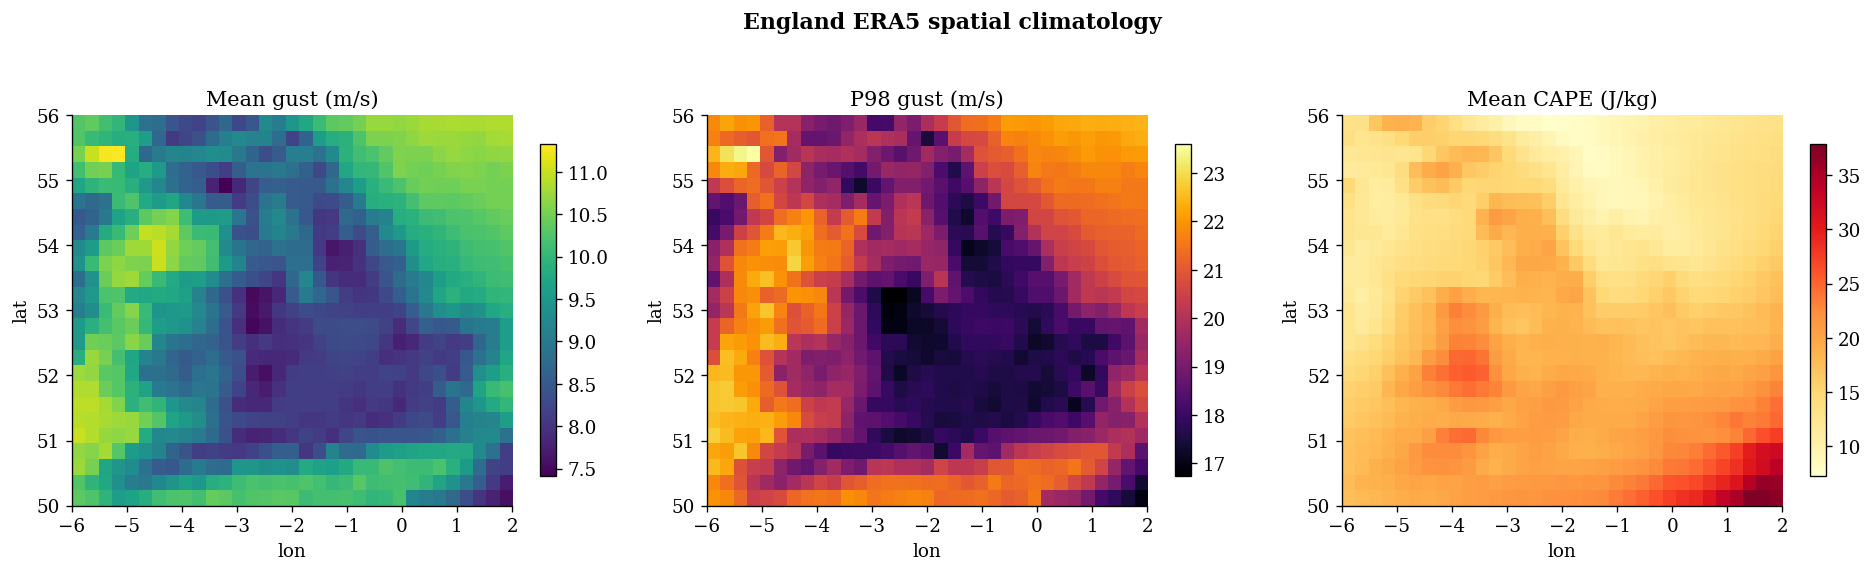

In [12]:
# spatial maps: mean gust and P98 gust over the full grid
mean_map = FIELDS["gust"].mean(axis=0)
p98_map = np.nanpercentile(FIELDS["gust"], 98, axis=0)
cape_map = FIELDS["cape"].mean(axis=0) if "cape" in FIELDS else np.zeros_like(mean_map)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
ext = [lons.min(), lons.max(), lats.min(), lats.max()]
for a, (M, ttl, cm) in zip(ax, [(mean_map, "Mean gust (m/s)", "viridis"),
                                (p98_map, "P98 gust (m/s)", "inferno"),
                                (cape_map, "Mean CAPE (J/kg)", "YlOrRd")]):
    im = a.imshow(M, origin="lower", extent=ext, aspect="auto", cmap=cm)
    a.set_title(ttl); a.set_xlabel("lon"); a.set_ylabel("lat")
    plt.colorbar(im, ax=a, shrink=0.85)
plt.suptitle("England ERA5 spatial climatology", y=1.03, fontweight="bold")
plt.tight_layout(); plt.savefig(BASE/"eda_spatial_maps.png", bbox_inches="tight"); plt.show()

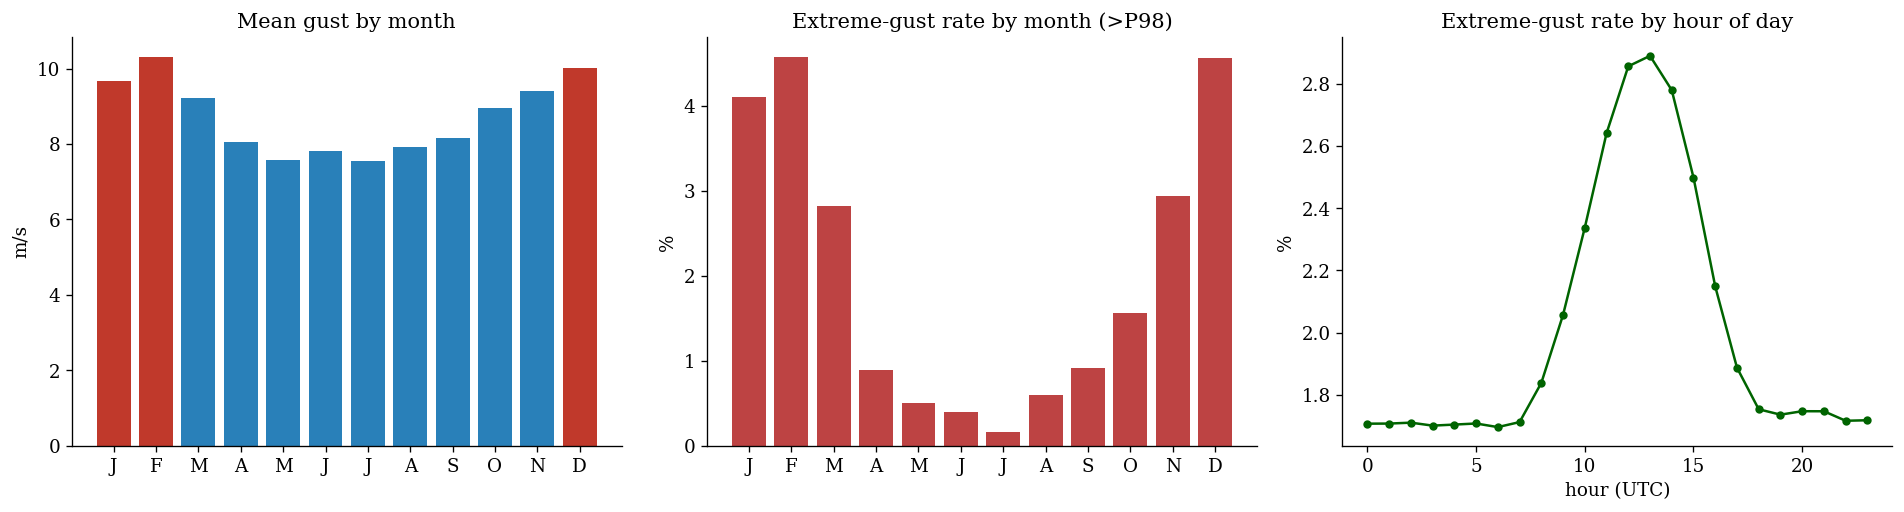

Winter share of P98 exceedances: 55.1%  | summer(JJA): 4.8%


In [13]:
# seasonal + diurnal structure of extreme gusts
p98_global = np.nanpercentile(gust_cells, 98)
exceed = gust_cells > p98_global                       # (T, N_CELLS) boolean
exc_rate_month = np.array([exceed[month == m].mean() for m in range(1, 13)])
exc_rate_hour = np.array([exceed[hour == h].mean() for h in range(24)])
gust_month = np.array([gust_cells[month == m].mean() for m in range(1, 13)])

fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
mlab = ["J","F","M","A","M","J","J","A","S","O","N","D"]
ax[0].bar(range(1, 13), gust_month, color=["#c0392b" if m in (12,1,2) else "#2980b9" for m in range(1,13)])
ax[0].set_xticks(range(1,13)); ax[0].set_xticklabels(mlab); ax[0].set_title("Mean gust by month"); ax[0].set_ylabel("m/s")

ax[1].bar(range(1, 13), 100*exc_rate_month, color="firebrick", alpha=0.85)
ax[1].set_xticks(range(1,13)); ax[1].set_xticklabels(mlab); ax[1].set_title("Extreme-gust rate by month (>P98)"); ax[1].set_ylabel("%")

ax[2].plot(range(24), 100*exc_rate_hour, "-o", color="darkgreen", ms=4)
ax[2].set_xlabel("hour (UTC)"); ax[2].set_title("Extreme-gust rate by hour of day"); ax[2].set_ylabel("%")
plt.tight_layout(); plt.savefig(BASE/"eda_seasonal_diurnal.png", bbox_inches="tight"); plt.show()
print("Winter share of P98 exceedances: "
      f"{100*exceed[np.isin(month,[12,1,2])].sum()/exceed.sum():.1f}%  "
      f"| summer(JJA): {100*exceed[np.isin(month,[6,7,8])].sum()/exceed.sum():.1f}%")

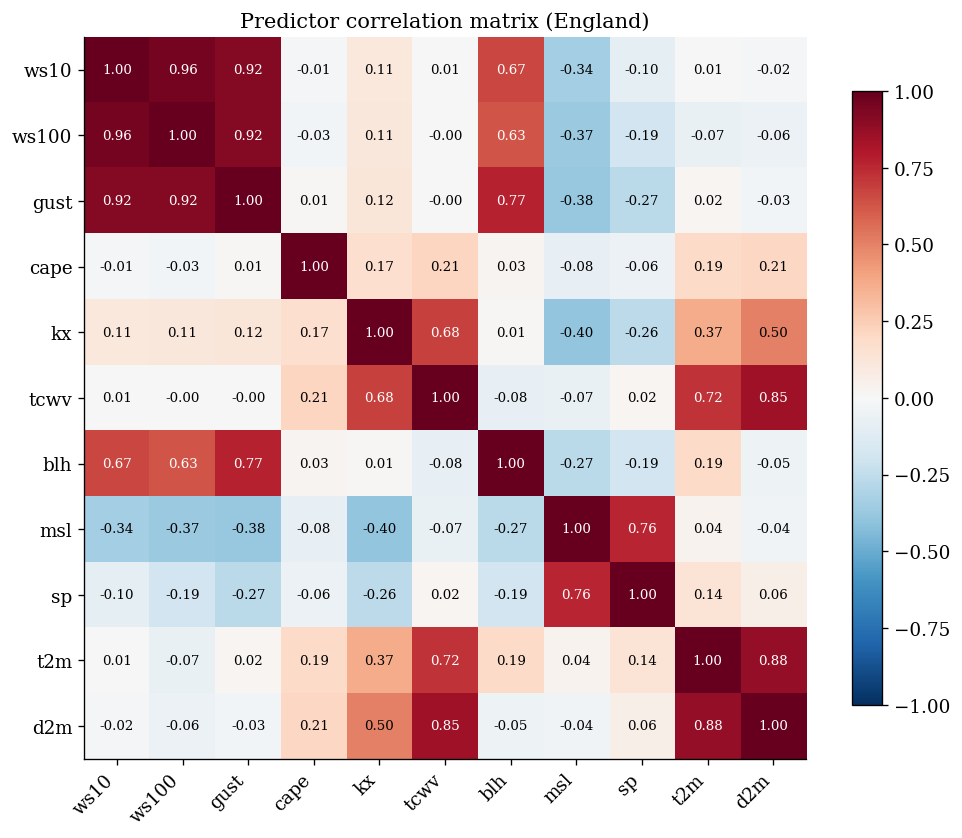

In [14]:
# predictor correlations with gust (spatially pooled, subsampled for speed)
cand = ["ws10","ws100","gust","cape","kx","tcwv","blh","msl","sp","t2m","d2m"]
cand = [c for c in cand if c in FIELDS]
sub = slice(None, None, max(1, T//20000))
mat = np.column_stack([FIELDS[c][sub][:, cell_ii, cell_jj].ravel() for c in cand])
corr = np.corrcoef(mat, rowvar=False)

fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cand))); ax.set_xticklabels(cand, rotation=45, ha="right")
ax.set_yticks(range(len(cand))); ax.set_yticklabels(cand)
for i in range(len(cand)):
    for j in range(len(cand)):
        ax.text(j, i, f"{corr[i,j]:.2f}", ha="center", va="center",
                fontsize=8, color="white" if abs(corr[i,j])>0.6 else "black")
plt.colorbar(im, shrink=0.85); ax.set_title("Predictor correlation matrix (England)")
plt.tight_layout(); plt.savefig(BASE/"eda_correlation.png", bbox_inches="tight"); plt.show()

In [15]:
def exceedance_events(series, thr, min_gap=CFG.DECLUS_HRS):
    """Declustered exceedance peaks: indices + peak values. Runs method with min_gap separation."""
    exc = series > thr
    if not exc.any():
        return np.array([], dtype=int), np.array([], dtype=np.float32)
    peaks, in_run, start = [], False, 0
    for t in range(len(series)):
        if exc[t] and not in_run:
            in_run, start = True, t
        elif not exc[t] and in_run:
            in_run = False
            peaks.append(start + int(np.argmax(series[start:t])))
    if in_run:
        peaks.append(start + int(np.argmax(series[start:])))
    merged = [peaks[0]]
    for pk in peaks[1:]:
        if pk - merged[-1] >= min_gap:
            merged.append(pk)
        elif series[pk] > series[merged[-1]]:
            merged[-1] = pk
    merged = np.array(merged, dtype=int)
    return merged, series[merged].astype(np.float32)

Reference cell index 471: mean gust 11.32, max 44.62 m/s


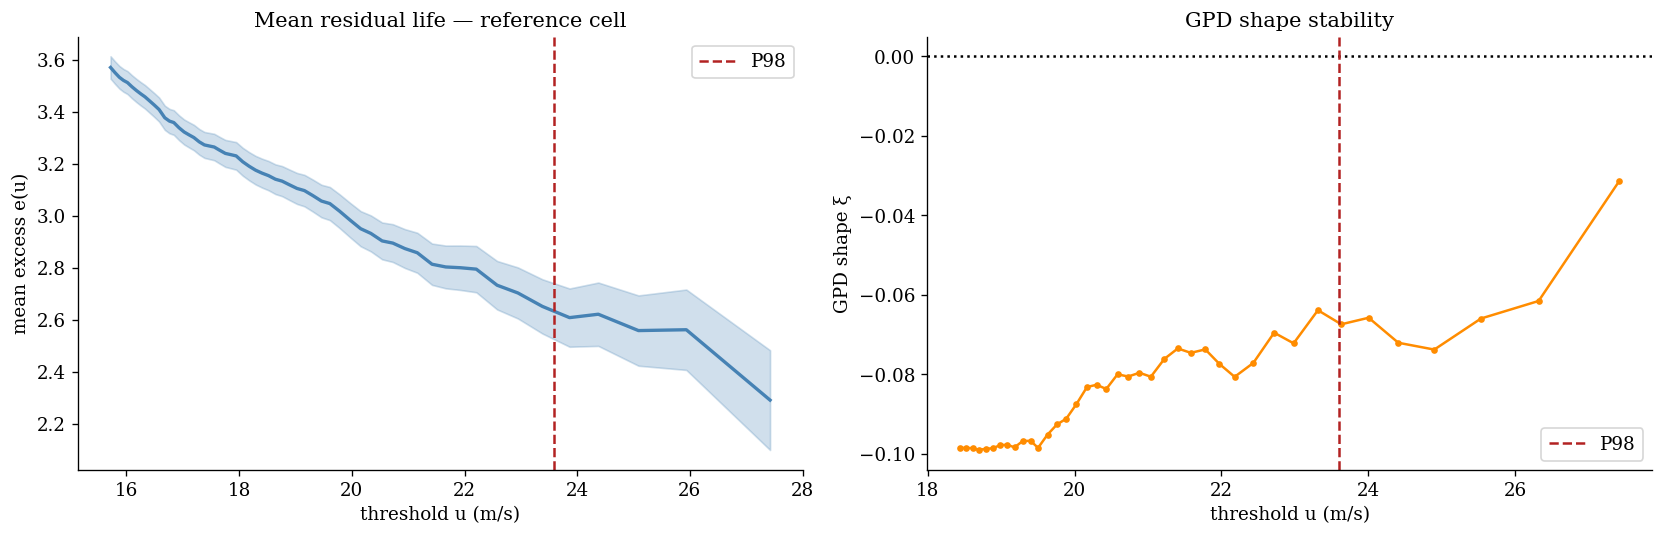

In [18]:
from scipy.stats import genpareto

# reference = windiest modelled cell
ref_k = int(np.argmax(gust_cells.mean(axis=0)))
ref = gust_cells[:, ref_k].astype(float)
print(f"Reference cell index {ref_k}: mean gust {ref.mean():.2f}, max {ref.max():.2f} m/s")

def mrl(x, qs=np.linspace(0.80, 0.995, 60)):
    us = np.nanquantile(x, qs); me, lo, hi = [], [], []
    for u in us:
        e = x[x > u] - u
        if len(e) < 15: me.append(np.nan); lo.append(np.nan); hi.append(np.nan); continue
        m = e.mean(); s = e.std(ddof=1)/np.sqrt(len(e))
        me.append(m); lo.append(m-1.96*s); hi.append(m+1.96*s)
    return us, np.array(me), np.array(lo), np.array(hi)

us, me, lo, hi = mrl(ref)
xi_path = []
uq = np.nanquantile(ref, np.linspace(0.90, 0.995, 40))
for u in uq:
    e = ref[ref > u] - u
    if len(e) < 40: xi_path.append(np.nan); continue
    xi, _, _ = genpareto.fit(e, floc=0); xi_path.append(xi)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
ax[0].plot(us, me, color="steelblue", lw=2); ax[0].fill_between(us, lo, hi, alpha=0.25, color="steelblue")
ax[0].axvline(np.nanpercentile(ref, 98), color="firebrick", ls="--", label="P98")
ax[0].set_xlabel("threshold u (m/s)"); ax[0].set_ylabel("mean excess e(u)"); ax[0].set_title("Mean residual life — reference cell"); ax[0].legend()
ax[1].plot(uq, xi_path, "-o", color="darkorange", ms=3); ax[1].axhline(0, color="k", ls=":")
ax[1].axvline(np.nanpercentile(ref, 98), color="firebrick", ls="--", label="P98")
ax[1].set_xlabel("threshold u (m/s)"); ax[1].set_ylabel("GPD shape ξ"); ax[1].set_title("GPD shape stability"); ax[1].legend()
plt.tight_layout(); plt.savefig(BASE/"evt_threshold_diagnostics.png", bbox_inches="tight"); plt.show()

GPD @P98=23.60 m/s | ξ=-0.081  σ=3.773  | 228 declustered events


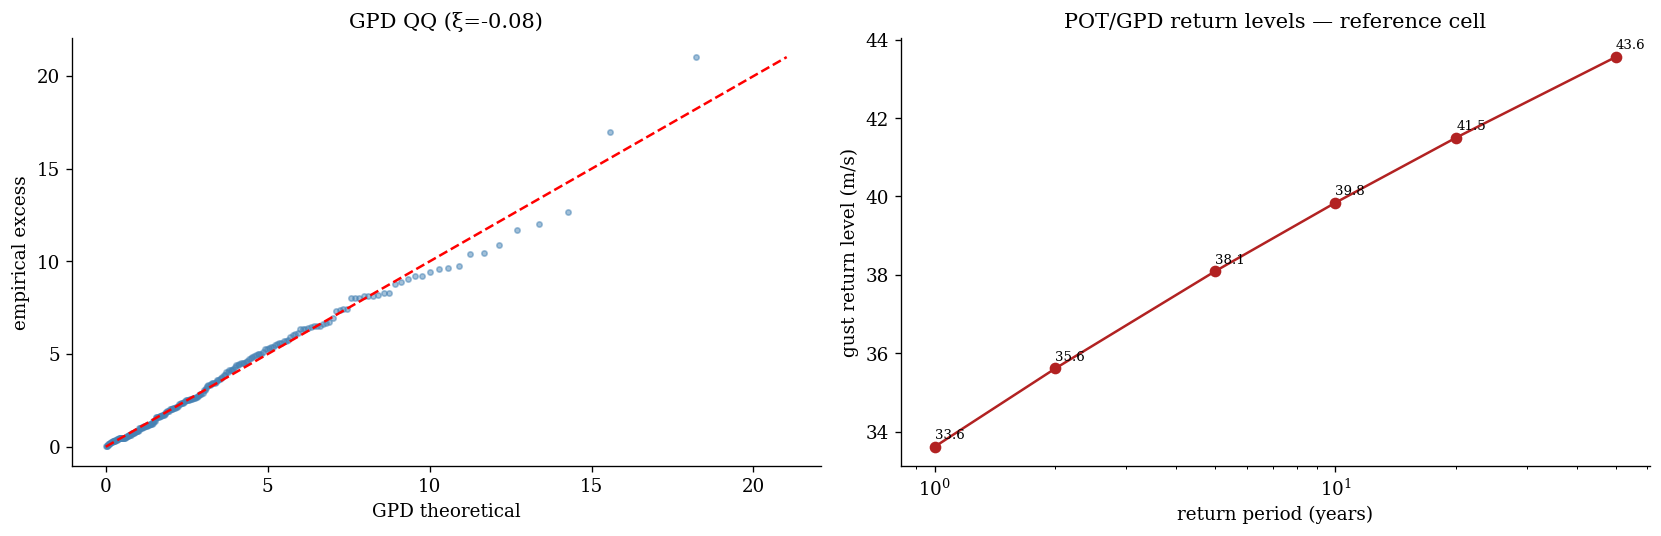

In [19]:
# GPD fit at P98 + QQ plot + return levels (declustered exceedances)
u98 = np.nanpercentile(ref, 98)
idx, pk = exceedance_events(ref, u98)
exc = np.sort(pk - u98)
xi, loc, scale = genpareto.fit(exc, floc=0)
print(f"GPD @P98={u98:.2f} m/s | ξ={xi:+.3f}  σ={scale:.3f}  | {len(exc)} declustered events")

n = len(exc); probs = (np.arange(1, n+1)-0.5)/n
theo = genpareto.ppf(probs, c=xi, loc=0, scale=scale)

# return levels: events/year -> level with GPD
years = (times[-1]-times[0]).days/365.25
rate = len(exc)/years                      # events per year
Tret = np.array([1, 2, 5, 10, 20, 50])
m = rate*Tret
rl = u98 + (scale/xi)*((m)**xi - 1) if abs(xi) > 1e-6 else u98 + scale*np.log(m)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
ax[0].scatter(theo, exc, s=10, alpha=0.5, color="steelblue")
mx = max(theo.max(), exc.max()); ax[0].plot([0,mx],[0,mx],"r--")
ax[0].set_xlabel("GPD theoretical"); ax[0].set_ylabel("empirical excess"); ax[0].set_title(f"GPD QQ (ξ={xi:+.2f})")
ax[1].plot(Tret, rl, "-o", color="firebrick"); ax[1].set_xscale("log")
ax[1].set_xlabel("return period (years)"); ax[1].set_ylabel("gust return level (m/s)"); ax[1].set_title("POT/GPD return levels — reference cell")
for t, r in zip(Tret, rl): ax[1].annotate(f"{r:.1f}", (t, r), fontsize=8, xytext=(0,5), textcoords="offset points")
plt.tight_layout(); plt.savefig(BASE/"evt_gpd_returnlevels.png", bbox_inches="tight"); plt.show()

In [20]:
# Ferro-Segers intervals estimator of the extremal index theta (clustering strength)
def extremal_index(series, thr):
    t_exc = np.where(series > thr)[0]
    if len(t_exc) < 3: return np.nan
    S = np.diff(t_exc).astype(float)           # inter-exceedance times
    if (S > 2).any():
        num = 2*(S.sum())**2
        den = len(S)*np.sum(S*(S-1)) if np.sum(S*(S-1)) > 0 else np.nan
        theta = num/den
    else:
        num = 2*(np.sum(S-1))**2
        den = len(S)*np.sum((S-1)*(S-2))
        theta = num/den if den > 0 else np.nan
    return float(np.clip(theta, 0, 1))

# a representative subset of 60 cells
show_idx = np.linspace(0, N_CELLS-1, min(N_CELLS, 60)).astype(int)
thetas = [extremal_index(gust_cells[:, k], np.nanpercentile(gust_cells[:, k], 98)) for k in show_idx]
thetas = np.array([t for t in thetas if np.isfinite(t)])
print(f"Extremal index θ  median={np.median(thetas):.2f}  (mean cluster size ≈ {1/np.median(thetas):.1f} h)")
print(f"=> θ<1 confirms temporal clustering; declustering gap of {CFG.DECLUS_HRS} h is appropriate.")

Extremal index θ  median=0.07  (mean cluster size ≈ 14.2 h)
=> θ<1 confirms temporal clustering; declustering gap of 24 h is appropriate.


In [21]:
nlat, nlon = len(lats), len(lons)
ncell = nlat*nlon
eps = 1e-6

# synoptic spatial fields from MSLP
GRID_KM = CFG.GRID*111.32
dlat_km = GRID_KM
dlon_km = np.maximum(GRID_KM*np.cos(np.deg2rad(lats)), 1e-3)
msl = FIELDS["msl"]
gy = np.gradient(msl, axis=1)/dlat_km
gx = np.gradient(msl, axis=2)/dlon_km[None,:,None]
pgf = np.sqrt(gx*gx+gy*gy).astype(np.float32)
lap = (np.gradient(gy,axis=1)+np.gradient(gx,axis=2)).astype(np.float32)
f_cor = np.maximum(2*7.292e-5*np.abs(np.sin(np.deg2rad(lats))), 2e-5)[None,:,None]
vgeo = (pgf*100.0/1000.0/(1.225*f_cor)).astype(np.float32)
msl_tend = np.zeros_like(msl); msl_tend[3:] = msl[3:]-msl[:-3]

# kinematic
ws10, ws100, gustf = FIELDS["ws10"], FIELDS["ws100"], FIELDS["gust"]
shear = (ws100-ws10).astype(np.float32)
wdir = np.arctan2(FIELDS["v10"], FIELDS["u10"])
def tend(a,k=3):
    o=np.zeros_like(a); o[k:]=a[k:]-a[:-k]; return o
# convective
cape=FIELDS["cape"]; sqrt_cape=np.sqrt(np.clip(cape,0,None)).astype(np.float32)
wmaxshear=(np.sqrt(2*np.clip(cape,0,None))*shear).astype(np.float32)
dd=(FIELDS["t2m"]-FIELDS["d2m"]).astype(np.float32)
print("Synoptic + kinematic + convective fields ready:", pgf.shape)

Synoptic + kinematic + convective fields ready: (100772, 25, 33)


In [22]:
# The chronological split is needed here: every statistic used to build a feature
# (state threshold, ADI, CV2) is estimated on the training period only. The running
# state (time since last event, rolling counts) is causal and spans the whole record.
tstamp     = times.values.astype("datetime64[ns]")
_span      = tstamp[-1] - tstamp[0]
train_end  = tstamp[0] + _span*CFG.TRAIN_FRAC
val_end    = tstamp[0] + _span*(CFG.TRAIN_FRAC + CFG.VAL_FRAC)
is_train_t = tstamp <= train_end
print(f"Split for feature statistics: train <= {str(train_end)[:10]}")

# intermittency state on the FULL grid
g2 = gustf.reshape(T, ncell)
thr_all = np.nanpercentile(g2[is_train_t], 98, axis=0)      # (ncell,) TRAIN-period threshold
exc = g2 > thr_all[None,:]
tsl = np.zeros_like(g2); last = np.full(ncell, -9999)
for t in range(T):
    tsl[t] = t-last; last = np.where(exc[t], t, last)
tsl = np.clip(tsl, 0, 24*30).astype(np.float32)
log_tsl = np.log1p(tsl).reshape(T,nlat,nlon)
win = 24*7
cs = np.cumsum(exc.astype(np.float32), axis=0)
roll7 = np.zeros_like(cs); roll7[win:]=cs[win:]-cs[:-win]; roll7[:win]=cs[:win]
roll7 = roll7.reshape(T,nlat,nlon)
# static ADI / CV2 per cell (broadcast over time)
tr_idx = np.flatnonzero(is_train_t); n_tr = tr_idx.size
exc_tr = exc[is_train_t]
nexc = np.maximum(exc_tr.sum(0),1)
adi_static = (n_tr/nexc).astype(np.float32)
cv2_static = np.ones(ncell, np.float32)
for c in range(ncell):
    v = g2[tr_idx[exc_tr[:,c]], c]
    if len(v) > 2: cv2_static[c] = (v.std(ddof=1)/(v.mean()+eps))**2
adi_map = np.broadcast_to(adi_static.reshape(nlat,nlon)[None], (T,nlat,nlon)).astype(np.float32)
cv2_map = np.broadcast_to(cv2_static.reshape(nlat,nlon)[None], (T,nlat,nlon)).astype(np.float32)
# temporal broadcast
mo=times.month.values.astype(np.float32); ho=times.hour.values.astype(np.float32)
def bc(v): return np.broadcast_to(v[:,None,None], (T,nlat,nlon)).astype(np.float32)
sin_m,cos_m=bc(np.sin(2*np.pi*mo/12)),bc(np.cos(2*np.pi*mo/12))
sin_h,cos_h=bc(np.sin(2*np.pi*ho/24)),bc(np.cos(2*np.pi*ho/24))
print("Intermittency + temporal maps ready. ADI median", np.median(adi_static).round(1))

Split for feature statistics: train <= 2023-01-18
Intermittency + temporal maps ready. ADI median 50.0


In [23]:
# advective tendency of the gust field:  ADV = -(u . grad) q,  units (m/s) per hour
# Centred differences on the sphere; dlon shrinks with latitude, which is why the zonal spacing is
# taken per row rather than as a constant.
_ggy = np.gradient(gustf, axis=1) / dlat_km
_ggx = np.gradient(gustf, axis=2) / dlon_km[None, :, None]
adv_map = (-(3.6*FIELDS["u10"]*_ggx + 3.6*FIELDS["v10"]*_ggy)).astype(np.float32)
ADV_PHYS = adv_map.copy()          # kept unstandardised for the PDE residual
del _ggy, _ggx
print(f"advection channel: mean |ADV| = {np.abs(adv_map).mean():.3f} (m/s)/h")

# assemble the channel stack
CH = {
    # convective
    "cape":cape, "sqrt_cape":sqrt_cape, "kx":FIELDS["kx"],
    "tcwv":FIELDS["tcwv"], "dd":dd, "wmaxshear":wmaxshear,
    # synoptic
    "msl":msl, "pgf":pgf, "lap":lap, "vgeo":vgeo, "msl_tend":msl_tend,
    # kinematic
    "ws10":ws10, "ws100":ws100, "gust":gustf, "gust_factor":gustf/(ws10+eps),
    "shear":shear, "wdir_sin":np.sin(wdir).astype(np.float32), "wdir_cos":np.cos(wdir).astype(np.float32),
    "ws10_tend":tend(ws10), "adv":adv_map, "blh":FIELDS["blh"], "t2m":FIELDS["t2m"],
    # intermittency + seasonal
    "log_tsl":log_tsl, "roll7":roll7, "adi":adi_map, "cv2":cv2_map,
    "sin_m":sin_m, "cos_m":cos_m, "sin_h":sin_h, "cos_h":cos_h,
}
CH_NAMES = list(CH.keys())
C = len(CH_NAMES)
MAPS = np.stack([CH[k] for k in CH_NAMES], axis=1).astype(np.float32)   # (T, C, nlat, nlon)
print("Map stack:", MAPS.shape, "| channels:", C)

# interpretable linear subset (matches the model equation)
LINEAR_NAMES = ["log_tsl","roll7","adi","cv2","cape","shear","wmaxshear",
                "pgf","msl_tend","adv","sin_m","cos_m","sin_h","cos_h"]
LINEAR_IDX = [CH_NAMES.index(n) for n in LINEAR_NAMES]
print("Linear hazard channels:", LINEAR_NAMES)

# free big intermediates
del gy,gx,pgf,lap,vgeo,msl_tend,g2,exc,cs,roll7,tsl,log_tsl,adi_map,cv2_map,sin_m,cos_m,sin_h,cos_h,adv_map
gc.collect()

advection channel: mean |ADV| = 0.521 (m/s)/h
Map stack: (100772, 30, 25, 33) | channels: 30
Linear hazard channels: ['log_tsl', 'roll7', 'adi', 'cv2', 'cape', 'shear', 'wmaxshear', 'pgf', 'msl_tend', 'adv', 'sin_m', 'cos_m', 'sin_h', 'cos_h']


7646

In [24]:
tstamp = times.values.astype("datetime64[ns]")
span = tstamp[-1]-tstamp[0]
train_end = tstamp[0]+span*CFG.TRAIN_FRAC
val_end   = tstamp[0]+span*(CFG.TRAIN_FRAC+CFG.VAL_FRAC)
is_train_t = tstamp <= train_end
print(f"Split: train <= {str(train_end)[:10]} | val <= {str(val_end)[:10]} | test after")

gust_full = FIELDS["gust"]                                          # (T,nlat,nlon)
thr_full = np.nanpercentile(gust_full[is_train_t], CFG.POT_Q*100, axis=0).astype(np.float32)  # (nlat,nlon)
print(f"Train P{int(CFG.POT_Q*100)} threshold: mean {thr_full.mean():.2f}  [{thr_full.min():.1f},{thr_full.max():.1f}] m/s")

# forward rolling max over (t, t+LEAD]
fm = np.full_like(gust_full, -np.inf)
for d in range(1, CFG.LEAD+1):
    fm[:T-d] = np.maximum(fm[:T-d], gust_full[d:])
OCC_MAP = (fm > thr_full[None]).astype(np.float32)                  # (T,nlat,nlon)
EXC_MAP = np.clip(fm - thr_full[None], 0.0, None).astype(np.float32)
print("Base occurrence rate (all cells/times): %.2f%%" % (OCC_MAP.mean()*100))

Split: train <= 2023-01-18 | val <= 2024-10-08 | test after
Train P98 threshold: mean 19.93  [16.8,23.9] m/s
Base occurrence rate (all cells/times): 7.91%


In [26]:
# normalise channels using TRAIN timesteps only
CH_MEAN = MAPS[is_train_t].mean(axis=(0,2,3)).astype(np.float32)
CH_STD  = (MAPS[is_train_t].std(axis=(0,2,3))+1e-6).astype(np.float32)
MAPS = ((MAPS - CH_MEAN[None,:,None,None]) / CH_STD[None,:,None,None]).astype(np.float32)
print("MAPS normalised. NaNs:", int(np.isnan(MAPS).sum()))

# excess normalisation (for a stable severity scale; GPD works on raw excess but we log for reporting)
pos_train = (OCC_MAP[is_train_t] > 0.5)
EXC_SCALE = float(np.median(EXC_MAP[is_train_t][pos_train])) if pos_train.any() else 1.0
print("Median train excess (m/s):", round(EXC_SCALE,3))

MAPS normalised. NaNs: 0
Median train excess (m/s): 2.194


In [27]:
# origin-time samples, split by time
origins = np.arange(CFG.HIST-1, T - CFG.LEAD, CFG.SAMPLE_STRIDE)   # full (t, t+LEAD]
o_time = tstamp[origins]
split = np.where(o_time<=train_end, 0, np.where(o_time<=val_end, 1, 2))
tr_o, va_o, te_o = origins[split==0], origins[split==1], origins[split==2]
print(f"Origins — train {len(tr_o)} | val {len(va_o)} | test {len(te_o)}")

# physical fields kept for the PDE residual (never standardised)
GUST_PHYS = FIELDS["gust"].astype(np.float32)
DQ_TRUE = np.zeros_like(GUST_PHYS)
DQ_TRUE[:-1] = GUST_PHYS[1:] - GUST_PHYS[:-1]        # observed one hour tendency
ADV_T = torch.from_numpy(ADV_PHYS)
DQ_T = torch.from_numpy(DQ_TRUE)
print(f"tendency targets: mean |dq| = {np.abs(DQ_TRUE).mean():.3f} m/s per hour")

MAPS_T = torch.from_numpy(MAPS)                     # (T,C,nlat,nlon) shared
OCC_T  = torch.from_numpy(OCC_MAP)                  # (T,nlat,nlon)
EXC_T  = torch.from_numpy(EXC_MAP)
LIN_IDX_T = torch.tensor(LINEAR_IDX, dtype=torch.long)
HIST = CFG.HIST

# land+coastal mask so occurrence is scored on the SAME cells as the gradient-boosted model (fair comparison).
# The ConvGRU still ingests the full contiguous field; only the loss and metrics are masked.
LAND_MASK = torch.from_numpy(np.asarray(land_mask, dtype=bool))     # (nlat,nlon)
N_LAND = int(LAND_MASK.sum())
print(f"Scoring cells (land+coastal): {N_LAND}/{nlat*nlon}")

class FieldDS(Dataset):
    def __init__(self, origins): self.o = origins
    def __len__(self): return len(self.o)
    def __getitem__(self, i):
        t = int(self.o[i])
        x = MAPS_T[t-HIST+1:t+1]                    # (H,C,nlat,nlon)
        return x, OCC_T[t], EXC_T[t], ADV_T[t], DQ_T[t]

NW = 2 if DEVICE.type=="cuda" else 0
dl_tr = DataLoader(FieldDS(tr_o), batch_size=CFG.BATCH, shuffle=True,  num_workers=NW, pin_memory=True, drop_last=True)
dl_va = DataLoader(FieldDS(va_o), batch_size=CFG.BATCH, shuffle=False, num_workers=NW, pin_memory=True)
dl_te = DataLoader(FieldDS(te_o), batch_size=CFG.BATCH, shuffle=False, num_workers=NW, pin_memory=True)
xb, ob, eb, ab, db = next(iter(dl_tr))
print("Batch:", xb.shape, ob.shape, eb.shape, ab.shape, db.shape)
prev = float(OCC_MAP[is_train_t].mean())
print(f"Train prevalence {prev*100:.2f}%")

Origins — train 23498 | val 5039 | test 5030
tendency targets: mean |dq| = 0.604 m/s per hour
Scoring cells (land+coastal): 520/825
Batch: torch.Size([16, 48, 30, 25, 33]) torch.Size([16, 25, 33]) torch.Size([16, 25, 33]) torch.Size([16, 25, 33]) torch.Size([16, 25, 33])
Train prevalence 8.24%


In [28]:
class ConvGRUCell(nn.Module):
    def __init__(self, in_ch, hid, k=3):
        super().__init__(); p=k//2
        self.z = nn.Conv2d(in_ch+hid, hid, k, padding=p)
        self.r = nn.Conv2d(in_ch+hid, hid, k, padding=p)
        self.n = nn.Conv2d(in_ch+hid, hid, k, padding=p)
        self.hid = hid
    def forward(self, x, h):
        xh = torch.cat([x,h],1)
        z = torch.sigmoid(self.z(xh)); r = torch.sigmoid(self.r(xh))
        n = torch.tanh(self.n(torch.cat([x, r*h],1)))
        return (1-z)*n + z*h

class HybridHazard(nn.Module):
    def __init__(self, C, lin_idx, hid=24, k=3, dropout=0.3, xi_clamp=0.4, xi_init=-0.13):
        super().__init__()
        self.register_buffer("lin_idx", lin_idx)
        self.cell = ConvGRUCell(C, hid, k)
        self.hid = hid; self.xi_clamp = xi_clamp
        self.drop = nn.Dropout2d(dropout)
        n_lin = len(lin_idx)
        self.lin_occ = nn.Conv2d(n_lin, 1, 1)     # beta coefficients (occurrence)
        self.ai_occ  = nn.Conv2d(hid, 1, 1)
        self.lin_sev = nn.Conv2d(n_lin, 1, 1)     # gamma coefficients (severity)
        self.ai_sev  = nn.Conv2d(hid, 1, 1)
        self.aux_dq  = nn.Conv2d(hid, 1, 1)   # one hour gust tendency, m/s
        # start the GPD shape near the EVT estimate (xi = xi_clamp*tanh(xi_raw))
        xi0 = float(np.arctanh(np.clip(xi_init/xi_clamp, -0.99, 0.99)))
        self.xi_raw  = nn.Parameter(torch.tensor([xi0], dtype=torch.float32))
        nn.init.zeros_(self.ai_occ.weight); nn.init.zeros_(self.ai_sev.weight)
    def forward(self, x):                          # x: (B,H,C,nlat,nlon)
        B,H,C,Hh,W = x.shape
        h = torch.zeros(B, self.hid, Hh, W, device=x.device, dtype=x.dtype)
        for t in range(H):
            h = self.cell(x[:,t], h)
        h = self.drop(h)
        last = x[:,-1]
        xlin = last.index_select(1, self.lin_idx)  # (B,n_lin,nlat,nlon)
        eta_lin = self.lin_occ(xlin)
        eta_ai  = self.ai_occ(h)
        logit = (eta_lin + eta_ai).squeeze(1)      # (B,nlat,nlon)
        log_sigma = (self.lin_sev(xlin) + self.ai_sev(h)).squeeze(1)
        sigma = F.softplus(log_sigma) + 1e-3
        xi = self.xi_clamp*torch.tanh(self.xi_raw)  # bounded shape
        dq = self.aux_dq(h).squeeze(1)              # (B,nlat,nlon) predicted tendency
        return logit, sigma, xi, eta_lin.squeeze(1), eta_ai.squeeze(1), dq

model = HybridHazard(C, LIN_IDX_T, CFG.HID, CFG.KSIZE, CFG.DROPOUT, CFG.XI_CLAMP, CFG.XI_INIT).to(DEVICE)
n_par = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model); print(f"\nTrainable parameters: {n_par:,}")

HybridHazard(
  (cell): ConvGRUCell(
    (z): Conv2d(54, 24, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (r): Conv2d(54, 24, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (n): Conv2d(54, 24, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  )
  (drop): Dropout2d(p=0.3, inplace=False)
  (lin_occ): Conv2d(14, 1, kernel_size=(1, 1), stride=(1, 1))
  (ai_occ): Conv2d(24, 1, kernel_size=(1, 1), stride=(1, 1))
  (lin_sev): Conv2d(14, 1, kernel_size=(1, 1), stride=(1, 1))
  (ai_sev): Conv2d(24, 1, kernel_size=(1, 1), stride=(1, 1))
  (aux_dq): Conv2d(24, 1, kernel_size=(1, 1), stride=(1, 1))
)

Trainable parameters: 35,170


In [29]:
def focal_bce(logit, target, gamma, pos_weight):
    p = torch.sigmoid(logit)
    ce = F.binary_cross_entropy_with_logits(logit, target, reduction="none", pos_weight=pos_weight)
    pt = torch.where(target>0.5, p, 1-p)
    return ((1-pt)**gamma*ce).mean()

def gpd_nll(excess, sigma, xi, mask):
    """Negative log-likelihood of GPD(sigma, xi) on positive excesses only."""
    if mask.sum() < 1: return sigma.sum()*0.0
    y = excess[mask]; s = sigma[mask]
    xi_v = xi.expand_as(y)
    small = xi_v.abs() < 1e-4
    z = 1.0 + xi_v*y/s
    z = torch.clamp(z, min=1e-6)
    nll_gpd = torch.log(s) + (1.0 + 1.0/torch.where(small, torch.ones_like(xi_v), xi_v))*torch.log(z)
    nll_exp = torch.log(s) + y/s               # xi -> 0 limit
    return torch.where(small, nll_exp, nll_gpd).mean()

prev = float(OCC_MAP[is_train_t].mean())
POS_WEIGHT = torch.tensor([min(max((1-prev)/max(prev,1e-4),1.0),50.0)], device=DEVICE)
print(f"pos_weight {POS_WEIGHT.item():.1f}")

pos_weight 11.1


In [30]:
from sklearn.metrics import average_precision_score
opt = torch.optim.AdamW(model.parameters(), lr=CFG.LR, weight_decay=CFG.WEIGHT_DECAY)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=CFG.EPOCHS, eta_min=CFG.LR*0.02)
use_scaler = (DEVICE.type=="cuda" and AMP_DTYPE==torch.float16)
scaler = torch.cuda.amp.GradScaler(enabled=use_scaler)
CKPT = BASE/"heich_best.pt"
CKPT_MAG = BASE/"heich_best_mag.pt"      # second checkpoint, selected on severity

# Quantiles of GPD(sigma, xi), used to score severity the same way the strength
# section does, so the magnitude checkpoint is chosen on the reported quantity.
QT_LEVELS = np.asarray(getattr(CFG, "QUANTILES", (0.1, 0.25, 0.5, 0.75, 0.9)), dtype=np.float64)

def gpd_quant(sig, xi, taus):
    sig = np.asarray(sig, dtype=np.float64).reshape(-1, 1)
    xi = float(xi)
    t = np.asarray(taus, dtype=np.float64).reshape(1, -1)
    if abs(xi) > 1e-6:
        return sig / xi * ((1.0 - t) ** (-xi) - 1.0)
    return -sig * np.log(1.0 - t)

def crps_quant(obs, q, taus):
    d = np.asarray(obs, dtype=np.float64)[:, None] - q
    t = np.asarray(taus, dtype=np.float64)[None, :]
    pb = np.mean(np.maximum(t * d, (t - 1.0) * d), axis=0)
    return float(2.0 * (np.trapezoid(pb, taus) if hasattr(np, "trapezoid") else np.trapz(pb, taus)))

LM = LAND_MASK.to(DEVICE)                       # (nlat,nlon) bool

def physics_terms(dq_pred, dq_true, adv, mask, dt):
    """Auxiliary data term and PDE residual for the advective transport equation.

    The residual is  R = dq_pred - ADV*dt , i.e. the departure of the predicted tendency from the
    tendency that pure advection would produce. It is a soft prior, not a hard constraint: a gust
    field also has source and sink terms, so the weight is deliberately small.
    """
    dqp = dq_pred[:, mask]; dqt = dq_true[:, mask]; a = adv[:, mask]
    l_aux = F.mse_loss(dqp, dqt)
    l_phys = F.mse_loss(dqp, a*dt)
    return l_aux, l_phys

def step(x, occ, exc, adv, dq_true, train):
    x=x.to(DEVICE,non_blocking=True); occ=occ.to(DEVICE); exc=exc.to(DEVICE)
    adv=adv.to(DEVICE); dq_true=dq_true.to(DEVICE)
    with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=DEVICE.type=="cuda"):
        logit, sigma, xi, _, _, dq = model(x)
        # restrict loss to land+coastal cells
        lo = logit[:, LM]; oc = occ[:, LM]; sg = sigma[:, LM]; ex = exc[:, LM]
        mask = oc > 0.5
        l_occ = focal_bce(lo, oc, CFG.FOCAL_GAMMA, POS_WEIGHT)
        l_sev = gpd_nll(ex, sg, xi, mask)
        if CFG.USE_PHYSICS:
            l_aux, l_phys = physics_terms(dq, dq_true, adv, LM, CFG.DT_HOURS)
        else:
            l_aux = l_phys = torch.zeros((), device=logit.device)
        loss = (l_occ + CFG.LAMBDA_SEV*l_sev
                + CFG.LAMBDA_AUX*l_aux + CFG.LAMBDA_PHYS*l_phys)
    if train:
        opt.zero_grad(set_to_none=True)
        if use_scaler:
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(),1.0); scaler.step(opt); scaler.update()
        else:
            loss.backward(); nn.utils.clip_grad_norm_(model.parameters(),1.0); opt.step()
    return (float(loss), float(l_occ), float(l_sev), float(l_aux), float(l_phys),
            torch.sigmoid(logit).detach()[:, LM], sg.detach(), ex.detach(), float(xi))

def run(dl, train):
    model.train() if train else model.eval()
    agg=np.zeros(5); n=0; ps=[]; ys=[]; sgs=[]; exs=[]; xi_last=0.0
    lm_cpu = LAND_MASK
    ctx = torch.enable_grad() if train else torch.no_grad()
    with ctx:
        for x,occ,exc,adv,dqt in dl:
            loss,lo,ls,la,lp,p,sg,ex,xiv = step(x,occ,exc,adv,dqt,train)
            bs=x.size(0); agg+=np.array([loss,lo,ls,la,lp])*bs; n+=bs
            if not train:
                ps.append(p.float().cpu().numpy().ravel())
                ys.append(occ[:, lm_cpu].numpy().ravel())
                sgs.append(sg.float().cpu().numpy().ravel())
                exs.append(ex.float().cpu().numpy().ravel())
                xi_last = xiv
    agg/=max(n,1); ap=np.nan; crps=np.nan
    if not train and ys:
        yy=np.concatenate(ys); pp=np.concatenate(ps)
        ap = average_precision_score(yy,pp) if len(np.unique(yy))>1 else float(yy.mean())
        ss=np.concatenate(sgs); ee=np.concatenate(exs); pos = yy > 0.5
        if pos.sum() > 100:
            crps = crps_quant(ee[pos], gpd_quant(ss[pos], xi_last, QT_LEVELS), QT_LEVELS)
    return agg, ap, crps

In [31]:
# Two checkpoints are kept: one selected on validation PR-AUC (occurrence) and one
# on validation severity CRPS. Training stops once neither has improved for
# PATIENCE epochs.
hist={"tr":[],"va":[],"ap":[],"crps":[]}; best=-1; best_mag=np.inf; best_mag_ep=-1; wait=0
print(f"{'ep':>3} {'train':>8} {'val':>8} {'occ':>7} {'sev':>7} {'aux':>7} {'phys':>7} {'valPR':>7} {'xi':>6}")
print("-"*58)
for ep in range(1,CFG.EPOCHS+1):
    tr,_,_=run(dl_tr,True); va,ap,crps=run(dl_va,False); sched.step()
    xi_now=float(CFG.XI_CLAMP*np.tanh(model.xi_raw.item()))
    hist["tr"].append(tr[0]); hist["va"].append(va[0]); hist["ap"].append(ap)
    hist["crps"].append(crps)
    imp = ap>best+1e-4
    if imp: best=ap; torch.save(model.state_dict(),CKPT)
    imp_mag = np.isfinite(crps) and crps < best_mag-1e-9
    if imp_mag:
        best_mag=crps; best_mag_ep=ep; torch.save(model.state_dict(),CKPT_MAG)
    wait = 0 if (imp or imp_mag) else wait+1
    if ep%2==0 or ep==1 or imp:
        print(f"{ep:>3} {tr[0]:>8.4f} {va[0]:>8.4f} {va[1]:>7.4f} {va[2]:>7.4f} {va[3]:>7.4f} {va[4]:>7.4f} {ap:>7.4f} {xi_now:>6.2f}{'  *' if imp else ''}")
    if wait>=CFG.PATIENCE:
        print(f"Early stop @ep{ep} (best val PR-AUC {best:.4f})"); break
print("Best val PR-AUC:", round(best,4))
print(f"Magnitude checkpoint: epoch {best_mag_ep}, val severity CRPS {best_mag:.4f}")

 ep    train      val     occ     sev     aux    phys   valPR     xi
----------------------------------------------------------
  1   2.8182   1.0570  0.1674  0.7177  0.4861  0.5201  0.5367  -0.11  *
  2   2.2775   1.0710  0.1661  0.7390  0.4670  0.5160  0.5524  -0.13  *
  4   2.2570   1.2651  0.1703  0.9279  0.4695  0.5226  0.5400  -0.17
  6   2.2782   1.3294  0.1712  0.9916  0.4645  0.5440  0.5381  -0.21
  8   2.3031   1.3788  0.1739  1.0423  0.4506  0.5475  0.5188  -0.26
 10   2.3146   1.4306  0.1736  1.0916  0.4646  0.5219  0.5366  -0.32
 12   2.3214   1.5107  0.1786  1.1685  0.4535  0.5502  0.4951  -0.36
 14   2.2753   1.5843  0.1773  1.2436  0.4534  0.5483  0.5126  -0.38
Early stop @ep15 (best val PR-AUC 0.5524)
Best val PR-AUC: 0.5524
Magnitude checkpoint: epoch 3, val severity CRPS 1.1965


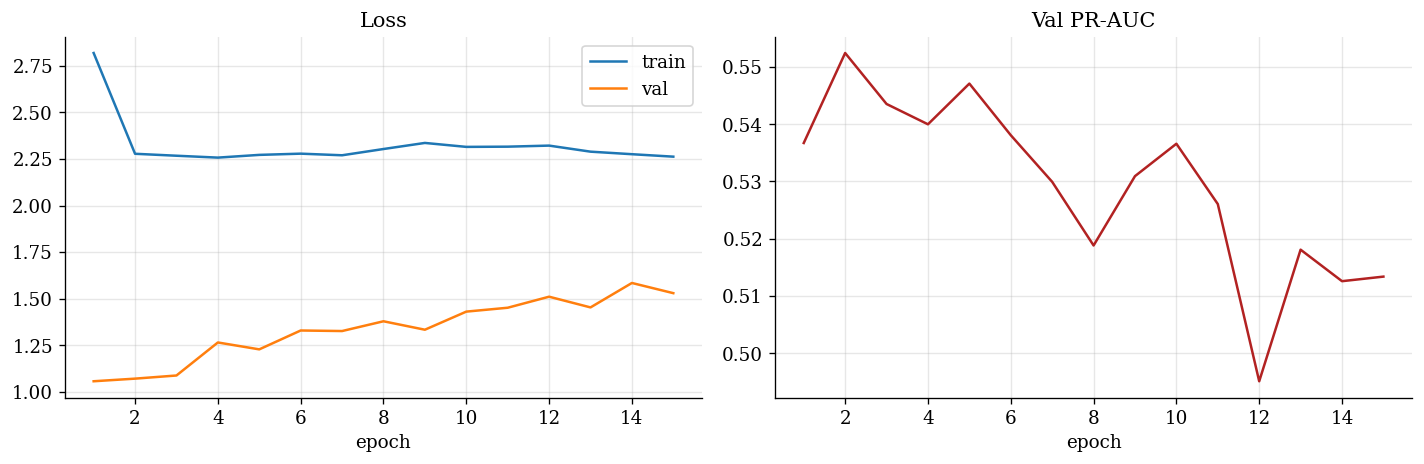

In [32]:
ep=np.arange(1,len(hist["tr"])+1)
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].plot(ep,hist["tr"],label="train"); ax[0].plot(ep,hist["va"],label="val")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].plot(ep,hist["ap"],color="firebrick"); ax[1].set_title("Val PR-AUC"); ax[1].set_xlabel("epoch"); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.savefig(BASE/"heich_train.png",bbox_inches="tight"); plt.show()

In [33]:
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, f1_score
from sklearn.metrics import precision_recall_curve
from sklearn.isotonic import IsotonicRegression

LMnp = LAND_MASK.numpy()
def flat(A): return A[:, LMnp].ravel()          # (N, nlat, nlon) -> land cells flattened

@torch.no_grad()
def predict(dl):
    model.eval(); P=[];LIN=[];AI=[];SIG=[];Y=[];E=[]
    for x,occ,exc,adv,dqt in dl:
        with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=DEVICE.type=="cuda"):
            logit,sigma,xi,el,ea,_ = model(x.to(DEVICE))
        P.append(torch.sigmoid(logit).float().cpu().numpy())
        LIN.append(torch.sigmoid(el).float().cpu().numpy())
        AI.append(torch.sigmoid(ea).float().cpu().numpy())
        SIG.append(sigma.float().cpu().numpy()); Y.append(occ.numpy()); E.append(exc.numpy())
    cat=lambda L: np.concatenate(L,0)
    return cat(P),cat(LIN),cat(AI),cat(SIG),cat(Y),cat(E), float(xi)

model.load_state_dict(torch.load(CKPT, map_location=DEVICE, weights_only=True))
P,LINP,AIP,SIG,Y,E,XI = predict(dl_te)
Pv,_,_,SIGv,Yv,Ev,_ = predict(dl_va)
yv, pv = flat(Yv), flat(Pv)
y = flat(Y)
# isotonic calibration fit on validation, applied to test
iso = IsotonicRegression(out_of_bounds="clip").fit(pv, yv)
p_hybrid = flat(P); p_hybrid_cal = iso.transform(p_hybrid)
op_thr = float(np.linspace(0.02,0.9,80)[int(np.argmax([f1_score(yv,(iso.transform(pv)>=th).astype(int),zero_division=0) for th in np.linspace(0.02,0.9,80)]))])
print(f"Test origins {P.shape[0]} | land cells {N_LAND} | xi={XI:+.3f} | op_thr {op_thr:.3f}")

Test origins 5030 | land cells 520 | xi=-0.125 | op_thr 0.265


In [34]:
def sedi(yv_,p,th):
    yh=(p>=th).astype(int)
    tp=((yh==1)&(yv_==1)).sum();fn=((yh==0)&(yv_==1)).sum();fp=((yh==1)&(yv_==0)).sum();tn=((yh==0)&(yv_==0)).sum()
    H=min(max(tp/max(tp+fn,1),1e-6),1-1e-6); Fr=min(max(fp/max(fp+tn,1),1e-6),1-1e-6)
    return (np.log(Fr)-np.log(H)-np.log(1-Fr)+np.log(1-H))/(np.log(Fr)+np.log(H)+np.log(1-Fr)+np.log(1-H))
def occ_metrics(yv_,p,th):
    prev=yv_.mean(); bs=brier_score_loss(yv_,p); bsc=brier_score_loss(yv_,np.full_like(p,prev))
    yh=(p>=th).astype(int); tp=((yh==1)&(yv_==1)).sum();fp=((yh==1)&(yv_==0)).sum();fn=((yh==0)&(yv_==1)).sum()
    prec=tp/max(tp+fp,1); rec=tp/max(tp+fn,1); f1=2*prec*rec/max(prec+rec,1e-9)
    csi=tp/max(tp+fp+fn,1); far=fp/max(tp+fp,1)
    return dict(ROC_AUC=roc_auc_score(yv_,p),PR_AUC=average_precision_score(yv_,p),
                BrierSkill=1-bs/bsc,Precision=prec,Recall=rec,F1=f1,CSI=csi,FAR=far,SEDI=sedi(yv_,p,th))

# persistence: current gust minus threshold, land-masked
persist = np.stack([gust_full[int(t)]-thr_full for t in te_o],0)[:, LMnp].ravel()
rows={"Climatology":np.full_like(y,y.mean(),dtype=float),
      "Persistence":1/(1+np.exp(-persist)),
      "Linear only":flat(LINP),
      "AI only":flat(AIP),
      "Hybrid (calibrated)":p_hybrid_cal}
tbl=pd.DataFrame({k:occ_metrics(y,np.clip(v,1e-6,1-1e-6),op_thr) for k,v in rows.items()}).T
tbl=tbl[["ROC_AUC","PR_AUC","BrierSkill","Precision","Recall","F1","CSI","FAR","SEDI"]]
print("="*92); print("OCCURRENCE — COMPARISON & ABLATION (test, land cells, calibrated hybrid)"); print("="*92)
print(tbl.round(4).to_string()); tbl.to_csv(BASE/"heich_v2_comparison.csv")

OCCURRENCE — COMPARISON & ABLATION (test, land cells, calibrated hybrid)
                     ROC_AUC  PR_AUC  BrierSkill  Precision  Recall      F1     CSI     FAR    SEDI
Climatology           0.5000  0.0770      0.0000     0.0000  0.0000  0.0000  0.0000  0.0000 -0.0000
Persistence           0.8067  0.4755      0.1845     0.7770  0.2704  0.4012  0.2509  0.2230  0.6059
Linear only           0.8320  0.4753     -1.7084     0.0791  0.9974  0.1465  0.0791  0.9209  0.2659
AI only               0.8020  0.2054     -1.4266     0.0801  0.9999  0.1484  0.0801  0.9199  0.4806
Hybrid (calibrated)   0.8911  0.5427      0.3070     0.4659  0.5531  0.5058  0.3385  0.5341  0.7056


In [35]:
# Export test predictions with their origin times, so that confidence intervals
# can be computed later by resampling whole time blocks: rows from the same
# storm are not independent, so row-level resampling would be too optimistic.
try:
    _preds = dict(rows)
    _y = y
    _t = np.repeat(np.asarray(tstamp[te_o]).astype("datetime64[h]").astype(np.int64),
                   int(LMnp.sum()))
    _path = BASE / "bootstrap_HEICH_v3.npz"
    _names = list(_preds)
    _P = np.stack([np.asarray(_preds[k], dtype=np.float32).ravel() for k in _names], 0)
    _y = np.asarray(_y).ravel().astype(np.int8)
    _t = np.asarray(_t).ravel().astype(np.int64)
    assert _P.shape[1] == _y.size == _t.size, (
        "row counts disagree -- the (origin, cell) layout is not what the export "
        "assumed: " + str((_P.shape, _y.size, _t.size)))
    np.savez_compressed(_path, P=_P, names=np.array(_names), y=_y, t=_t)
    print(f"bootstrap export -> {_path}")
    print(f"  {_P.shape[0]} series x {_y.size:,} rows | "
          f"{len(np.unique(_t // (24*14)))} fortnight blocks | base rate {_y.mean()*100:.2f}%")
except Exception as _e:
    print("!! bootstrap export failed (every result above is unaffected):", repr(_e))

bootstrap export -> /content/drive/MyDrive/MSc Dissertation/bootstrap_HEICH_v3.npz
  5 series x 2,615,600 rows | 46 fortnight blocks | base rate 7.70%


In [36]:
# inputs for the intermittent-demand baselines
_p1_ln     = np.flatnonzero(LMnp.ravel())
_P1_GUST2D = gust_full.reshape(gust_full.shape[0], -1)
_P1_THR1D  = thr_full.ravel().astype(np.float32)
_P1_LEAD   = CFG.LEAD
_P1_ROWS_VA = (np.repeat(va_o, _p1_ln.size), np.tile(_p1_ln, len(va_o)))
_P1_Y_VA    = yv
_P1_ROWS_TE = (np.repeat(te_o, _p1_ln.size), np.tile(_p1_ln, len(te_o)))
_P1_Y_TE    = y
_P1_EXC_TE  = flat(E)

# Intermittent-demand baselines: Croston, SBA and TSB.
# All three are causal. Smoothing constants are chosen on validation PR-AUC and
# the probabilities are isotonically calibrated on validation, as for the models.
# A per-hour rate r becomes a window probability 1 - (1 - r)^L.
try:
    from sklearn.metrics import roc_auc_score as _roc, average_precision_score as _ap
    from sklearn.metrics import brier_score_loss as _brier
    from sklearn.isotonic import IsotonicRegression as _Iso

    _ALPHAS = (0.05, 0.10, 0.20)
    _BETAS = (0.02, 0.05, 0.10)

    def _croston_states(gust2d, thr1d, keep_t, alpha, betas):
        """Causal Croston/SBA/TSB state at each t in keep_t, for every cell.

        Only the requested rows are retained, so memory tracks the evaluation
        set rather than the whole record.
        """
        T, N = gust2d.shape
        keep_t = np.asarray(keep_t)
        pos = np.full(T, -1, np.int64); pos[keep_t] = np.arange(keep_t.size)
        nb = len(betas)
        z_c = np.full(N, np.nan); p_c = np.full(N, np.nan); z_t = np.full(N, np.nan)
        q = np.zeros(N); prob = np.zeros((nb, N)); seen = np.zeros(N, bool)
        cro = np.zeros((keep_t.size, N), np.float32)
        siz = np.zeros((keep_t.size, N), np.float32)
        tsb = np.zeros((nb, keep_t.size, N), np.float32)
        tsz = np.zeros((keep_t.size, N), np.float32)
        bet = np.asarray(betas, dtype=np.float64).reshape(nb, 1)
        for t in range(T):
            g = gust2d[t]; e = g > thr1d
            q += 1.0
            if e.any():
                s = np.where(e, g - thr1d, 0.0)
                first = e & ~seen; upd = e & seen
                z_c = np.where(first, s, np.where(upd, alpha * s + (1 - alpha) * z_c, z_c))
                p_c = np.where(first, q, np.where(upd, alpha * q + (1 - alpha) * p_c, p_c))
                z_t = np.where(first, s, np.where(upd, alpha * s + (1 - alpha) * z_t, z_t))
                q = np.where(e, 0.0, q); seen = seen | e
            prob = prob + bet * (e[None, :].astype(np.float64) - prob)
            k = pos[t]
            if k >= 0:
                cro[k] = np.where(seen, 1.0 / np.maximum(p_c, 1.0), 0.0)
                siz[k] = np.where(seen, z_c, 0.0)
                tsb[:, k] = prob
                tsz[k] = np.where(seen, z_t, 0.0)
        return dict(cro=cro, siz=siz, tsb=tsb, tsz=tsz)

    def _win(rate, lead):
        r = np.clip(np.asarray(rate, dtype=np.float64), 0.0, 1.0)
        return (1.0 - (1.0 - r) ** lead).astype(np.float32)

    # bind the notebook's own arrays
    _G2, _THR1, _LEAD = _P1_GUST2D, _P1_THR1D, _P1_LEAD
    (_tv, _cv), _yva = _P1_ROWS_VA, np.asarray(_P1_Y_VA).ravel()
    (_tt, _ct), _yte = _P1_ROWS_TE, np.asarray(_P1_Y_TE).ravel()
    _keep = np.unique(np.concatenate([_tv, _tt]))
    _pk = np.full(_G2.shape[0], -1, np.int64); _pk[_keep] = np.arange(_keep.size)
    _iv, _it = _pk[_tv], _pk[_tt]
    print(f"Croston / SBA / TSB - {_G2.shape[1]} cells, {_keep.size:,} retained origins, "
          f"lead {_LEAD} h", flush=True)

    # one pass per alpha; states cached so nothing is refitted
    _ST = {}
    for _a in _ALPHAS:
        _t0 = time.time() if "time" in dir() else None
        _ST[_a] = _croston_states(_G2, _THR1, _keep, _a, _BETAS)
        print(f"  alpha={_a}: states built"
              + (f" ({time.time()-_t0:.0f}s)" if _t0 else ""), flush=True)

    _cand = {}
    for _a in _ALPHAS:
        _r = _ST[_a]["cro"][_iv, _cv]
        _cand.setdefault("Croston", []).append((_ap(_yva, _win(_r, _LEAD)), (_a, None)))
        _cand.setdefault("SBA", []).append((_ap(_yva, _win((1 - _a / 2) * _r, _LEAD)), (_a, None)))
        for _j, _b in enumerate(_BETAS):
            _cand.setdefault("TSB", []).append(
                (_ap(_yva, _win(_ST[_a]["tsb"][_j][_iv, _cv], _LEAD)), (_a, _b)))
    _best = {k: max(v, key=lambda r: r[0]) for k, v in _cand.items()}

    def _vec(nm, a, b, rows_i, rows_c):
        if nm == "Croston": return _win(_ST[a]["cro"][rows_i, rows_c], _LEAD)
        if nm == "SBA":     return _win((1 - a / 2) * _ST[a]["cro"][rows_i, rows_c], _LEAD)
        return _win(_ST[a]["tsb"][list(_BETAS).index(b)][rows_i, rows_c], _LEAD)

    def _size(nm, a, b, rows_i, rows_c):
        if nm == "TSB": return _ST[a]["tsz"][rows_i, rows_c]
        f = (1 - a / 2) if nm == "SBA" else 1.0
        return f * _ST[a]["siz"][rows_i, rows_c]

    # calibrate on validation, score on test
    _P1_PRED, _P1_SIZE, _rows_p1 = {}, {}, []
    _base = float(_yte.mean()); _bs_c = _brier(_yte, np.full(_yte.size, _base))
    for _nm, (_sv, (_a, _b)) in _best.items():
        _pv = _vec(_nm, _a, _b, _iv, _cv)
        _pt = _vec(_nm, _a, _b, _it, _ct)
        _iso = _Iso(out_of_bounds="clip").fit(_pv, _yva)
        _pc = np.clip(_iso.predict(_pt), 0, 1)
        _P1_PRED[_nm] = _pc.astype(np.float32)
        _P1_SIZE[_nm] = _size(_nm, _a, _b, _it, _ct)
        _rows_p1.append({"Model": _nm, "alpha": _a, "beta": _b,
                         "val PR": round(_sv, 4),
                         "ROC AUC": _roc(_yte, _pt), "PR AUC": _ap(_yte, _pt),
                         "Brier skill": 1 - _brier(_yte, _pc) / _bs_c})
    _rows_p1.append({"Model": "Climatology", "alpha": None, "beta": None, "val PR": None,
                     "ROC AUC": 0.5, "PR AUC": _base, "Brier skill": 0.0})
    print("\nINTERMITTENT-DEMAND BASELINES  (test, identical rows to the model above)")
    print(pd.DataFrame(_rows_p1).set_index("Model").round(4).to_string())
    print("\nCroston and SBA near climatology is the expected result: both estimate a")
    print("per-cell average RATE and barely vary in time, so they answer 'how often',")
    print("not 'when'. TSB decays through quiet spells and should separate from them.")

    # strength: expected excess vs observed, on true events
    if "_P1_EXC_TE" in dir():
        _exc = np.asarray(_P1_EXC_TE).ravel(); _pos = _yte > 0.5
        if _pos.sum() > 100:
            print("\nSTRENGTH - mean |error| in predicted excess on true events (m/s)")
            for _nm in _P1_SIZE:
                print(f"  {_nm:<9} {np.abs(_P1_SIZE[_nm][_pos] - _exc[_pos]).mean():.3f}")
            print(f"  {'climatol.':<9} "
                  f"{np.abs(_exc[_pos].mean() - _exc[_pos]).mean():.3f}")

    # append to the bootstrap export
    if "_path" in dir() and Path(str(_path)).exists():
        _z = np.load(str(_path))
        _keepn = [n for n in list(_z["names"]) if n not in _P1_PRED]
        _keepP = np.stack([_z["P"][list(_z["names"]).index(n)] for n in _keepn], 0)
        _P2 = np.concatenate([_keepP, np.stack([_P1_PRED[k] for k in _P1_PRED], 0)], 0)
        np.savez_compressed(str(_path), P=_P2.astype(np.float32),
                            names=np.array(_keepn + list(_P1_PRED)),
                            y=_z["y"], t=_z["t"])
        print(f"\nbootstrap export updated -> {_path}  ({_P2.shape[0]} series)")
    del _ST
except Exception as _e:
    import traceback; traceback.print_exc()
    print("!! intermittent baselines failed (every result above is unaffected):", repr(_e))

Croston / SBA / TSB - 825 cells, 10,069 retained origins, lead 24 h
  alpha=0.05: states built (3s)
  alpha=0.1: states built (3s)
  alpha=0.2: states built (3s)

INTERMITTENT-DEMAND BASELINES  (test, identical rows to the model above)
             alpha  beta  val PR  ROC AUC  PR AUC  Brier skill
Model                                                         
Croston       0.10   NaN  0.0883   0.5309  0.0832      -0.0025
SBA           0.10   NaN  0.0884   0.5309  0.0831      -0.0024
TSB           0.05   0.1  0.3253   0.7119  0.2980       0.1231
Climatology    NaN   NaN     NaN   0.5000  0.0770       0.0000

Croston and SBA near climatology is the expected result: both estimate a
per-cell average RATE and barely vary in time, so they answer 'how often',
not 'when'. TSB decays through quiet spells and should separate from them.

STRENGTH - mean |error| in predicted excess on true events (m/s)
  Croston   1.957
  SBA       1.960
  TSB       1.951
  climatol. 1.990

bootstrap export update

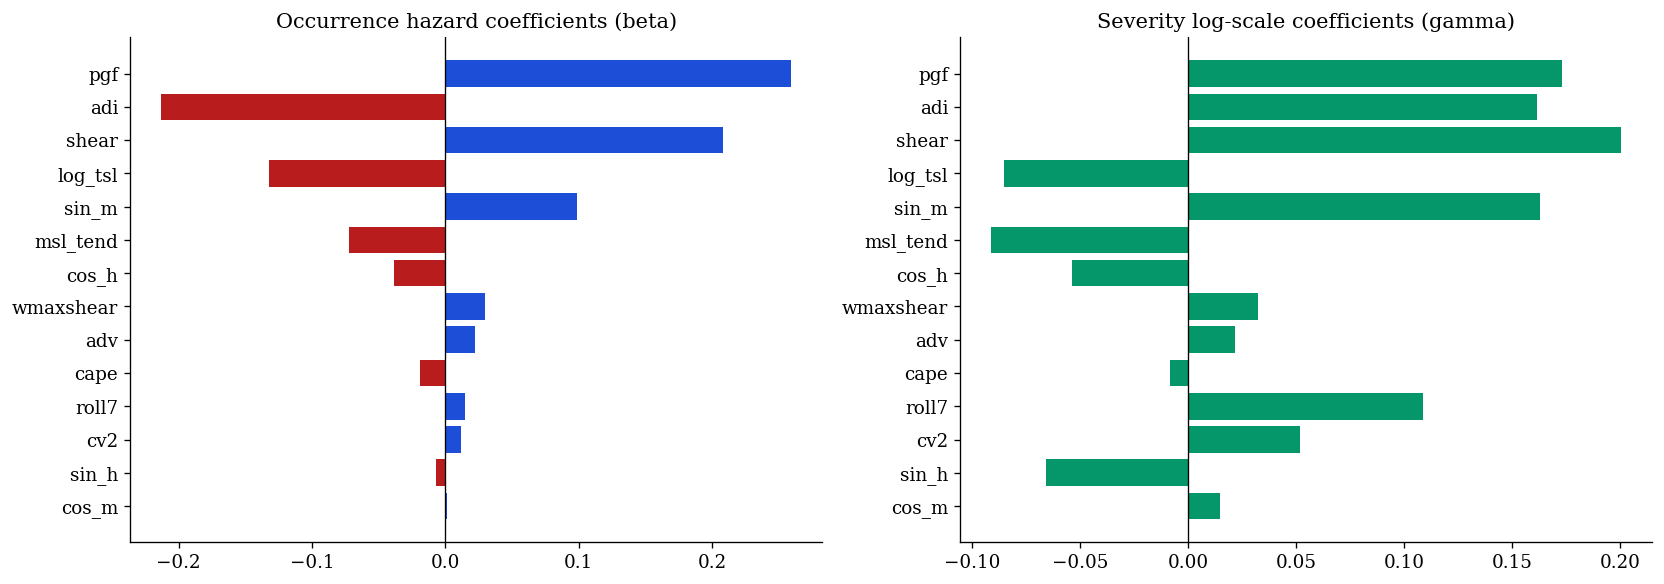

Most influential occurrence drivers: ['pgf', 'adi', 'shear', 'log_tsl', 'sin_m']


In [37]:
# interpretable coefficients
beta = model.lin_occ.weight.detach().cpu().numpy().reshape(-1)
gamma = model.lin_sev.weight.detach().cpu().numpy().reshape(-1)
order = np.argsort(np.abs(beta))
fig,ax=plt.subplots(1,2,figsize=(14,5))
ax[0].barh(np.array(LINEAR_NAMES)[order], beta[order], color=["#b91c1c" if b<0 else "#1d4ed8" for b in beta[order]])
ax[0].axvline(0,color="k",lw=0.8); ax[0].set_title("Occurrence hazard coefficients (beta)")
ax[1].barh(np.array(LINEAR_NAMES)[order], gamma[order], color="#059669")
ax[1].axvline(0,color="k",lw=0.8); ax[1].set_title("Severity log-scale coefficients (gamma)")
plt.tight_layout(); plt.savefig(BASE/"heich_v2_coefficients.png",bbox_inches="tight"); plt.show()
print("Most influential occurrence drivers:", [LINEAR_NAMES[i] for i in order[::-1][:5]])

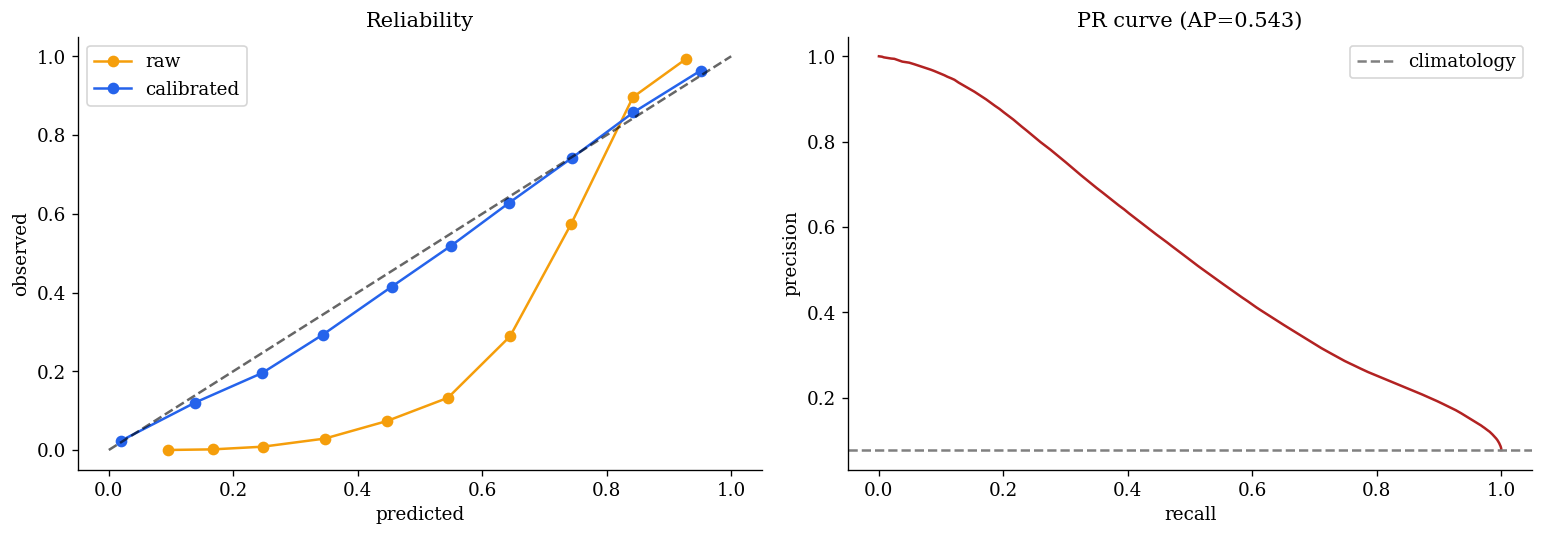

In [38]:
# reliability (raw vs calibrated) + PR curve
fig,ax=plt.subplots(1,2,figsize=(13,4.6))
for probs,lab,col in [(p_hybrid,"raw","#f59e0b"),(p_hybrid_cal,"calibrated","#2563eb")]:
    bins=np.linspace(0,1,11); ib=np.digitize(probs,bins)-1; xs,ys=[],[]
    for b in range(10):
        m=ib==b
        if m.sum()>200: xs.append(probs[m].mean()); ys.append(y[m].mean())
    ax[0].plot(xs,ys,"-o",label=lab,color=col)
ax[0].plot([0,1],[0,1],"k--",alpha=0.6); ax[0].set_xlabel("predicted"); ax[0].set_ylabel("observed"); ax[0].set_title("Reliability"); ax[0].legend()
pp,rr,_=precision_recall_curve(y,p_hybrid_cal)
ax[1].plot(rr,pp,color="firebrick"); ax[1].axhline(y.mean(),ls="--",color="gray",label="climatology")
ax[1].set_xlabel("recall"); ax[1].set_ylabel("precision"); ax[1].set_title(f"PR curve (AP={average_precision_score(y,p_hybrid_cal):.3f})"); ax[1].legend()
plt.tight_layout(); plt.savefig(BASE/"heich_v2_reliability.png",bbox_inches="tight"); plt.show()

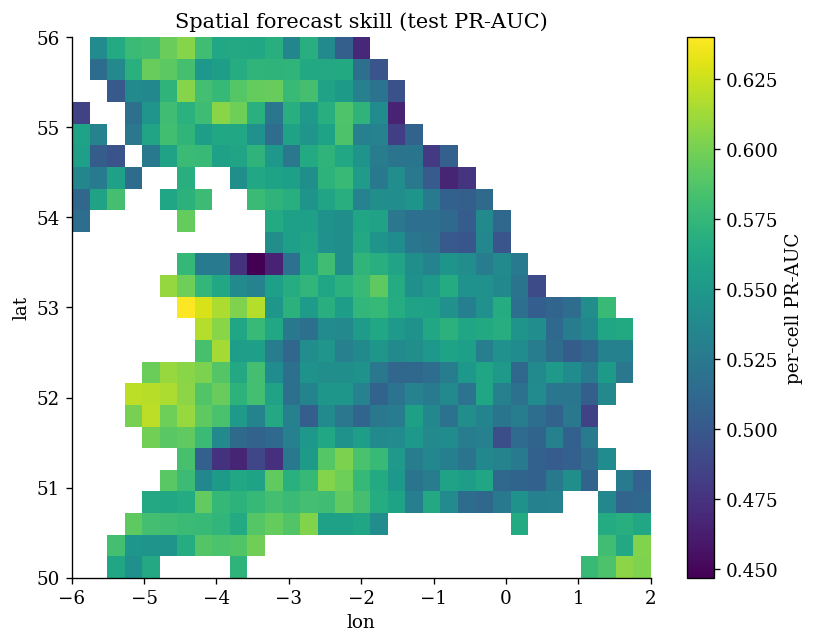

Median per-cell PR-AUC 0.550 vs climatology 0.077


In [39]:
# spatial skill map over land cells
Pc=P.reshape(P.shape[0],-1); Yc=Y.reshape(Y.shape[0],-1)
ap_cell=np.full(Pc.shape[1],np.nan)
for c in range(Pc.shape[1]):
    yc=Yc[:,c]
    if yc.sum()>=3 and yc.sum()<len(yc): ap_cell[c]=average_precision_score(yc,Pc[:,c])
skill=ap_cell.reshape(nlat,nlon); skill[~LMnp]=np.nan
fig,ax=plt.subplots(figsize=(7,5.5))
im=ax.imshow(skill,origin="lower",extent=[lons.min(),lons.max(),lats.min(),lats.max()],aspect="auto",cmap="viridis")
plt.colorbar(im,label="per-cell PR-AUC"); ax.set_title("Spatial forecast skill (test PR-AUC)")
ax.set_xlabel("lon"); ax.set_ylabel("lat")
plt.tight_layout(); plt.savefig(BASE/"heich_v2_spatial.png",bbox_inches="tight"); plt.show()
print("Median per-cell PR-AUC %.3f vs climatology %.3f"%(np.nanmedian(ap_cell), y.mean()))

Severity (positive land cells): n=201,360 | GPD xi=-0.125 | median-excess MAE=1.95 m/s


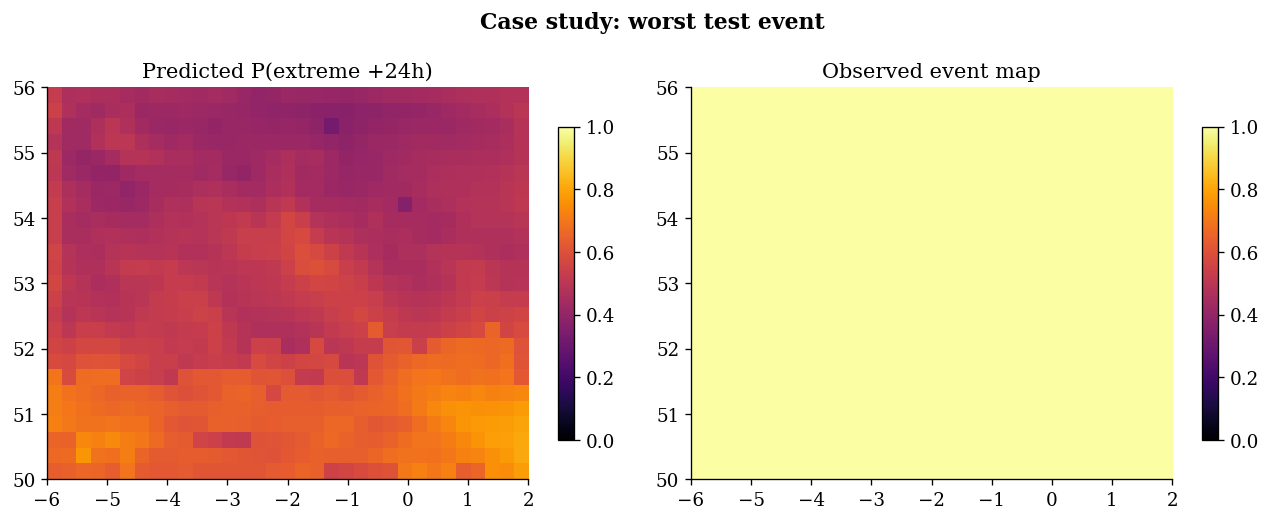

In [40]:
# GPD severity on positive land cells
Ymask = Y[:, LMnp]; Emask = E[:, LMnp]; Smask = SIG[:, LMnp]
m = Ymask.ravel()>0.5
sig=Smask.ravel()[m]; exc_true=Emask.ravel()[m]; xi=XI
med_pred = sig*((2.0**xi-1.0)/xi) if abs(xi)>1e-4 else sig*np.log(2.0)
mae_sev=np.abs(med_pred-exc_true).mean()
print(f"Severity (positive land cells): n={m.sum():,} | GPD xi={xi:+.3f} | median-excess MAE={mae_sev:.2f} m/s")

worst=int(np.argmax((E*LMnp[None]).reshape(E.shape[0],-1).sum(1)))
fig,ax=plt.subplots(1,2,figsize=(11,4.4)); ext=[lons.min(),lons.max(),lats.min(),lats.max()]
im0=ax[0].imshow(P[worst],origin="lower",extent=ext,aspect="auto",cmap="inferno",vmin=0,vmax=1); ax[0].set_title("Predicted P(extreme +24h)"); plt.colorbar(im0,ax=ax[0],shrink=0.8)
im1=ax[1].imshow(Y[worst],origin="lower",extent=ext,aspect="auto",cmap="inferno",vmin=0,vmax=1); ax[1].set_title("Observed event map"); plt.colorbar(im1,ax=ax[1],shrink=0.8)
plt.suptitle("Case study: worst test event",fontweight="bold")
plt.tight_layout(); plt.savefig(BASE/"heich_v2_case.png",bbox_inches="tight"); plt.show()

In [41]:
# Severity is scored from the checkpoint selected on validation severity CRPS.
# Two calibrations are fitted on validation exceedances only: a per-quantile shift
# (crossings repaired with a running maximum) and a split-conformal band on the
# outer interval, whose radius may be negative when the raw band over-covers.

def per_quantile_shift(q_val, y_val, taus):
    return np.array([np.quantile(y_val - q_val[:, k], taus[k]) for k in range(len(taus))])

def apply_shift(q, delta):
    return np.maximum.accumulate(q + delta[None, :], axis=1)

def conformal_radius(q_val, y_val, alpha):
    E = np.maximum(q_val[:, 0] - y_val, y_val - q_val[:, -1])
    n = E.size
    return float(np.quantile(E, min(1.0, np.ceil((n + 1) * (1 - alpha)) / n)))

ALPHA = 1.0 - (QT_LEVELS[-1] - QT_LEVELS[0])
MAG_CAL = {}

if CKPT_MAG.exists():
    model.load_state_dict(torch.load(CKPT_MAG, map_location=DEVICE, weights_only=True))
    _src = "magnitude checkpoint"
else:
    _src = "occurrence checkpoint (no magnitude checkpoint stored)"
_Pm, _, _, _SIGm, _Ym, _Em, _XIm = predict(dl_te)
_Pvm, _, _, _SIGvm, _Yvm, _Evm, _XIvm = predict(dl_va)
model.load_state_dict(torch.load(CKPT, map_location=DEVICE, weights_only=True))

_yv = flat(_Yvm); _sv = flat(_SIGvm); _ev = flat(_Evm)
_yt = flat(_Ym);  _st = flat(_SIGm);  _et = flat(_Em)
_pv, _pt = _yv > 0.5, _yt > 0.5

_qv = gpd_quant(_sv[_pv], _XIvm, QT_LEVELS)
_qt = gpd_quant(_st[_pt], _XIm, QT_LEVELS)
_ova, _ote = _ev[_pv], _et[_pt]

_delta = per_quantile_shift(_qv, _ova, QT_LEVELS)
_q_shift = apply_shift(_qt, _delta)
_rad = conformal_radius(_qv, _ova, ALPHA)
_q_band = _qt.copy(); _q_band[:, 0] -= _rad; _q_band[:, -1] += _rad
_q_band = np.maximum.accumulate(_q_band, axis=1)

# Held-out check. The shift is fitted on validation, so it always looks good
# there. Fit it on the first half of the validation exceedances and score the
# second half: if it does not help out of sample, it will not help on test.
_h = _ova.size // 2
_dA = per_quantile_shift(_qv[:_h], _ova[:_h], QT_LEVELS)
def _crps_(o, q):
    d = o[:, None] - q; t = QT_LEVELS[None, :]
    pb = np.mean(np.maximum(t * d, (t - 1.0) * d), axis=0)
    return float(2.0 * (np.trapezoid(pb, QT_LEVELS) if hasattr(np, "trapezoid")
                        else np.trapz(pb, QT_LEVELS)))
_rB = _crps_(_ova[_h:], _qv[_h:])
_sB = _crps_(_ova[_h:], apply_shift(_qv[_h:], _dA))
_verdict = ("shift helps out of sample, quote the calibrated row"
            if _sB < _rB else
            "SHIFT DOES NOT HELP OUT OF SAMPLE, quote the raw row")
print(f"   held-out validation CRPS: raw {_rB:.4f} -> shifted {_sB:.4f}   {_verdict}")
_cov = lambda q: float(np.mean((_ote >= q[:, 0]) & (_ote <= q[:, -1])))
MAG_CAL["ConvGRU hybrid"] = dict(q_raw=_qt, q_shift=_q_shift, q_band=_q_band,
                                 obs=_ote, delta=_delta, radius=_rad, src=_src)
print(f"ConvGRU hybrid   [{_src}]  xi={_XIm:+.3f}  n={_pt.sum():,}")
print("   per-quantile shift (m/s): "
      + "  ".join(f"{t:.2f}:{d:+.3f}" for t, d in zip(QT_LEVELS, _delta)))
print(f"   conformal band radius: {_rad:.3f} m/s")
print(f"   band coverage on test: raw {_cov(_qt):.3f} | shifted {_cov(_q_shift):.3f} | "
      f"conformal {_cov(_q_band):.3f}   (nominal {1-ALPHA:.2f})")

   held-out validation CRPS: raw 1.3211 -> shifted 1.2815   shift helps out of sample, quote the calibrated row
ConvGRU hybrid   [magnitude checkpoint]  xi=-0.139  n=201,360
   per-quantile shift (m/s): 0.10:+0.076  0.25:+0.203  0.50:+0.449  0.75:+0.757  0.90:+1.099
   conformal band radius: 0.109 m/s
   band coverage on test: raw 0.763 | shifted 0.813 | conformal 0.802   (nominal 0.80)


In [42]:
# inputs for the severity verification
# severity from the magnitude checkpoint, raw and calibrated side by side.
_S_TAUS  = QT_LEVELS
_S_OBS   = MAG_CAL["ConvGRU hybrid"]["obs"]
_s_etr, _s_otr = EXC_MAP[is_train_t][:, LMnp], OCC_MAP[is_train_t][:, LMnp]
_S_TRAIN = _s_etr[_s_otr > 0.5]
_S_PRED  = {"ConvGRU hybrid: raw":      MAG_CAL["ConvGRU hybrid"]["q_raw"],
            "ConvGRU hybrid: shifted":  MAG_CAL["ConvGRU hybrid"]["q_shift"]}

# Severity on true events: MAE, pinball loss and CRPS against the climatology of
# training-period excesses. The quantile grid spans 0.1-0.9, so the CRPS here is
# restricted to the central 80% (CRPS[10-90]). Skill % = 100 * (1 - model / clim).
try:
    _tau = np.asarray(_S_TAUS, dtype=np.float64)
    _obs = np.asarray(_S_OBS, dtype=np.float64).ravel()
    _tr = np.asarray(_S_TRAIN, dtype=np.float64).ravel()
    _tr = _tr[np.isfinite(_tr)]
    assert _obs.size > 50, f"only {_obs.size} scored events"

    def _pinball_vec(obs, q, tau):
        """Mean pinball loss per quantile level. obs (n,), q (n,K), tau (K,)."""
        d = obs[:, None] - q
        return np.mean(np.maximum(tau[None, :] * d, (tau[None, :] - 1.0) * d), axis=0)

    def _crps_from_pinball(pb, tau):
        """CRPS = 2 * integral of pinball over tau, trapezoid on the given grid."""
        return 2.0 * np.trapezoid(pb, tau) if hasattr(np, "trapezoid") \
            else 2.0 * np.trapz(pb, tau)

    # climatological reference: the same quantiles for every event
    _cq = np.quantile(_tr, _tau)
    _clim = np.repeat(_cq[None, :], _obs.size, axis=0)
    _pb_c = _pinball_vec(_obs, _clim, _tau)
    _crps_c = _crps_from_pinball(_pb_c, _tau)
    _mid = int(np.argmin(np.abs(_tau - 0.5)))
    _mae_c = float(np.abs(_obs - _cq[_mid]).mean())

    print("=" * 78)
    print(f"STRENGTH ON TRUE EVENTS  (n={_obs.size:,} exceedances, excess in m/s)")
    print(f"reference: climatology of {_tr.size:,} training-period excesses, "
          f"median {_cq[_mid]:.2f} m/s")
    print("=" * 78)

    _srows, _prows = [], []
    for _nm, _qp in _S_PRED.items():
        _q = np.asarray(_qp, dtype=np.float64)
        assert _q.shape == (_obs.size, _tau.size), f"{_nm}: {_q.shape} vs {(_obs.size, _tau.size)}"
        _q = np.sort(_q, axis=1)                      # enforce monotone quantiles
        _pb = _pinball_vec(_obs, _q, _tau)
        _crps = _crps_from_pinball(_pb, _tau)
        _mae = float(np.abs(_obs - _q[:, _mid]).mean())
        _cov = float(np.mean((_obs >= _q[:, 0]) & (_obs <= _q[:, -1])))
        _srows.append({"Model": _nm,
                       "MAE m/s": _mae, "MAE skill %": 100 * (1 - _mae / _mae_c),
                       "CRPS[10-90]": _crps, "CRPS skill %": 100 * (1 - _crps / _crps_c),
                       f"cover [{_tau[0]:.2f},{_tau[-1]:.2f}]": _cov,
                       "nominal": _tau[-1] - _tau[0]})
        for _i, _t in enumerate(_tau):
            _prows.append({"quantile": _t, "Model": _nm, "pinball": _pb[_i],
                           "climatology": _pb_c[_i],
                           "skill_%": 100 * (1 - _pb[_i] / _pb_c[_i])})

    _srows.append({"Model": "Climatology", "MAE m/s": _mae_c, "MAE skill %": 0.0,
                   "CRPS[10-90]": _crps_c, "CRPS skill %": 0.0,
                   f"cover [{_tau[0]:.2f},{_tau[-1]:.2f}]": np.nan,
                   "nominal": _tau[-1] - _tau[0]})
    _S_TABLE = pd.DataFrame(_srows).set_index("Model")
    print(_S_TABLE.round(4).to_string())

    print("\nPinball loss by quantile (m/s excess, lower is better)")
    _P_TABLE = pd.DataFrame(_prows).pivot(index="quantile", columns="Model",
                                          values="skill_%")
    print(_P_TABLE.round(4).to_string())

    if "BASE" in dir():
        _S_TABLE.to_csv(Path(str(BASE)) / "strength_verification.csv")
        print(f"\nwritten -> {Path(str(BASE)) / 'strength_verification.csv'}")
    elif "CFG" in dir() and hasattr(CFG, "CACHE"):
        _S_TABLE.to_csv(CFG.CACHE / "strength_verification.csv")
        print(f"\nwritten -> {CFG.CACHE / 'strength_verification.csv'}")
except Exception as _e:
    import traceback; traceback.print_exc()
    print("!! strength verification failed (every result above is unaffected):", repr(_e))

STRENGTH ON TRUE EVENTS  (n=201,360 exceedances, excess in m/s)
reference: climatology of 3,101,317 training-period excesses, median 2.23 m/s
                         MAE m/s  MAE skill %  CRPS[10-90]  CRPS skill %  cover [0.10,0.90]  nominal
Model                                                                                               
ConvGRU hybrid: raw       1.8833       2.0234       1.1916        2.2244             0.7633      0.8
ConvGRU hybrid: shifted   1.8159       5.5292       1.1467        5.9129             0.8132      0.8
Climatology               1.9222       0.0000       1.2187        0.0000                NaN      0.8

Pinball loss by quantile (m/s excess, lower is better)
Model     ConvGRU hybrid: raw  ConvGRU hybrid: shifted
quantile                                              
0.10                   0.4300                   1.0740
0.25                   1.0227                   2.6712
0.50                   2.0234                   5.5292
0.75                  

In [43]:
summary = {
    "data": "ERA5 England",
    "grid": [int(nlat), int(nlon)], "channels": int(C), "hist_h": CFG.HIST, "lead_h": CFG.LEAD,
    "params": int(sum(p.numel() for p in model.parameters())),
    "scoring_cells_land": int(N_LAND),
    "test_positive_rate": float(y.mean()),
    "hybrid_PR_AUC": float(tbl.loc["Hybrid (calibrated)","PR_AUC"]),
    "hybrid_BrierSkill": float(tbl.loc["Hybrid (calibrated)","BrierSkill"]),
    "linear_only_PR_AUC": float(tbl.loc["Linear only","PR_AUC"]),
    "ai_only_PR_AUC": float(tbl.loc["AI only","PR_AUC"]),
    "hybrid_SEDI": float(tbl.loc["Hybrid (calibrated)","SEDI"]),
    "gpd_xi": float(XI), "severity_MAE_ms": float(mae_sev),
    "best_val_PR_AUC": float(best),
}
with open(BASE/"heich_summary.json","w") as f: json.dump(summary,f,indent=2)
print(json.dumps(summary,indent=2))
print("\nPR-AUC by model:"); print(tbl["PR_AUC"].round(4).to_string())

{
  "data": "ERA5 England",
  "grid": [
    25,
    33
  ],
  "channels": 30,
  "hist_h": 48,
  "lead_h": 24,
  "params": 35170,
  "scoring_cells_land": 520,
  "test_positive_rate": 0.07698424905538559,
  "hybrid_PR_AUC": 0.5426682305034,
  "hybrid_BrierSkill": 0.30700342607444997,
  "linear_only_PR_AUC": 0.4752775226299578,
  "ai_only_PR_AUC": 0.2053882917082809,
  "hybrid_SEDI": 0.7055619454527982,
  "gpd_xi": -0.12537263333797455,
  "severity_MAE_ms": 1.9511445760726929,
  "best_val_PR_AUC": 0.5524166697693547
}

PR-AUC by model:
Climatology            0.0770
Persistence            0.4755
Linear only            0.4753
AI only                0.2054
Hybrid (calibrated)    0.5427
